In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Visualization configuration
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120

print("Football Analytics Environment Initialized.")

Football Analytics Environment Initialized.


In [2]:
# ==========================================
# 02. DATA INGESTION
# ==========================================

from google.colab import files

uploaded = files.upload()

file_name = "norwich_overall_clean.csv"

df = pd.read_csv(file_name)

print("Dataset successfully loaded.")
print(f"Total Records: {df.shape[0]}")
print(f"Total Features: {df.shape[1]}")

Saving norwich_overall_clean.csv to norwich_overall_clean (1).csv
Dataset successfully loaded.
Total Records: 26
Total Features: 49


In [3]:
# ==========================================
# 03. DATASET PROFILING
# ==========================================

print("DATASET STRUCTURE")
print("=" * 50)

display(df.head())

print("\nDATA TYPES")
display(df.dtypes)

print("\nSTATISTICAL SUMMARY")
display(df.describe().T)

DATASET STRUCTURE


,player_uid,player_name,club_name,kind,starts,substitute_appearances,minutes,rated_appearances,average_rating,goals,...,contract_wage,contract_end,contract_squad_status,contract_on_loan,left_foot,right_foot,goals_per_90_calc,assists_per_90_calc,xg_per_90_calc,xa_per_90_calc
0,21028821,Vladan Kovačević,Norwich City,overall,44,0,3956,44,6.920455,0,...,31500,2031-06-30,important_player,False,4,20,0.000000,0.000000,0.000000,0.000000
1,24065094,Ante Crnac,Norwich City,overall,9,12,951,17,7.064706,3,...,12000,2028-06-30,squad_player,False,20,6,0.283912,0.283912,0.221451,0.322713
2,27151182,Pelle Mattsson,Norwich City,overall,36,0,3186,36,7.230556,4,...,22173,2030-06-30,important_player,False,8,20,0.112994,0.056497,0.084463,0.082768
3,27161401,Mathias Kvistgaarden,Norwich City,overall,0,12,238,9,6.822222,1,...,17000,2029-06-30,squad_player,False,9,20,0.378151,0.756303,0.317647,0.196639
4,28086121,Jack Stacey,Norwich City,overall,13,4,1212,16,6.737500,0,...,25000,2027-06-30,squad_player,False,5,20,0.000000,0.074257,0.020792,0.103218



DATA TYPES


,0
player_uid,int64
player_name,object
club_name,object
kind,object
starts,int64
substitute_appearances,int64
minutes,int64
rated_appearances,int64
average_rating,float64
goals,int64



STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
player_uid,26.0,8.674905e+08,9.892036e+08,2.102882e+07,2.810489e+07,6.162496e+07,2.000071e+09,2.000192e+09
starts,26.0,2.115385e+01,1.584851e+01,0.000000e+00,5.750000e+00,1.950000e+01,3.525000e+01,4.400000e+01
substitute_appearances,26.0,3.961538e+00,4.275332e+00,0.000000e+00,0.000000e+00,2.500000e+00,6.750000e+00,1.400000e+01
minutes,26.0,1.903846e+03,1.380478e+03,9.000000e+01,5.340000e+02,1.684000e+03,3.065750e+03,3.961000e+03
rated_appearances,26.0,2.361538e+01,1.535728e+01,1.000000e+00,8.250000e+00,2.700000e+01,3.675000e+01,4.400000e+01
average_rating,26.0,7.067769e+00,2.380355e-01,6.400000e+00,6.981944e+00,7.078944e+00,7.217763e+00,7.600000e+00
goals,26.0,4.038462e+00,8.248543e+00,0.000000e+00,0.000000e+00,1.000000e+00,4.000000e+00,4.000000e+01
assists,26.0,3.576923e+00,4.867632e+00,0.000000e+00,0.000000e+00,2.000000e+00,5.250000e+00,1.800000e+01
expected_goals,26.0,3.138846e+00,5.861083e+00,0.000000e+00,4.625000e-01,9.900000e-01,2.827500e+00,2.730000e+01
non_penalty_expected_goals,26.0,2.980385e+00,5.429641e+00,0.000000e+00,4.625000e-01,9.900000e-01,2.827500e+00,2.483000e+01


In [4]:
# ==========================================
# 04. DATA QUALITY AUDIT
# ==========================================

# Check missing values
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("MISSING VALUE REPORT")
display(missing_summary)

# Check duplicate records
duplicate_count = df.duplicated().sum()

print(f"\nDuplicate Records: {duplicate_count}")

# Check player identity
print(f"Unique Players: {df['player_uid'].nunique()}")

MISSING VALUE REPORT


,Missing Values,Missing Percentage
pressures_attempted,26,100.00
pressures_completed,26,100.00
ability_potential_range_code,26,100.00
saves_held,23,88.46
saves_parried,23,88.46
saves_tipped,23,88.46
accomplished_positions,16,61.54



Duplicate Records: 0
Unique Players: 26


In [5]:
# ==========================================
# 05. SQUAD PERFORMANCE OVERVIEW
# ==========================================

performance_columns = [
    "player_name",
    "minutes",
    "goals",
    "assists",
    "expected_goals",
    "expected_assists",
    "average_rating"
]

available_columns = [
    col for col in performance_columns
    if col in df.columns
]

player_performance = df[available_columns].copy()

player_performance = player_performance.sort_values(
    by="minutes",
    ascending=False
)

display(player_performance.head(10))

,player_name,minutes,goals,assists,expected_goals,expected_assists,average_rating
15,Ruairi McConville,3961,3,0,1.95,0.58,7.093182
0,Vladan Kovačević,3956,0,0,0.00,0.00,6.920455
9,Harry Darling,3870,0,0,0.73,0.79,7.016279
12,Kenny McLean,3475,6,7,6.35,5.21,7.125000
21,Kellen Fisher,3288,1,18,0.53,10.35,7.223684
2,Pelle Mattsson,3186,4,2,2.99,2.93,7.230556
22,Oscar Schwartau,3089,10,12,8.21,9.57,7.245946
18,Ben Chrisene,2996,1,9,1.65,8.31,7.244444
16,Mohamed Touré,2856,40,3,27.30,2.47,7.371053
11,Darlin Yongwa,2854,0,6,0.54,3.62,7.026471


In [6]:
# ==========================================
# 06. PERFORMANCE NORMALIZATION
# ==========================================

metrics = [
    ("goals", "goals_per_90"),
    ("assists", "assists_per_90"),
    ("expected_goals", "xg_per_90"),
    ("expected_assists", "xa_per_90")
]

for source, target in metrics:
    if source in df.columns:
        df[target] = np.where(
            df["minutes"] > 0,
            df[source] / df["minutes"] * 90,
            np.nan
        )

display(
    df[
        [
            "player_name",
            "minutes",
            "goals_per_90",
            "assists_per_90",
            "xg_per_90",
            "xa_per_90"
        ]
    ].sort_values(
        by="goals_per_90",
        ascending=False
    ).head(10)
)

,player_name,minutes,goals_per_90,assists_per_90,xg_per_90,xa_per_90
16,Mohamed Touré,2856,1.260504,0.094538,0.860294,0.077836
17,Jovon Makama,1550,0.987097,0.116129,0.831484,0.080710
20,Papa Amadou Diallo,111,0.810811,0.000000,0.381081,0.591892
3,Mathias Kvistgaarden,238,0.378151,0.756303,0.317647,0.196639
22,Oscar Schwartau,3089,0.291356,0.349628,0.239204,0.278828
1,Ante Crnac,951,0.283912,0.283912,0.221451,0.322713
6,Sam Field,1236,0.218447,0.000000,0.126699,0.115049
10,Anthony Musaba,1818,0.198020,0.346535,0.199505,0.287129
12,Kenny McLean,3475,0.155396,0.181295,0.164460,0.134935
24,Jacob Wright,1350,0.133333,0.133333,0.105333,0.136667


In [7]:
# ==========================================
# 06. PERFORMANCE NORMALIZATION
# ==========================================

metrics = [
    ("goals", "goals_per_90"),
    ("assists", "assists_per_90"),
    ("expected_goals", "xg_per_90"),
    ("expected_assists", "xa_per_90")
]

for source, target in metrics:
    if source in df.columns:
        df[target] = np.where(
            df["minutes"] > 0,
            df[source] / df["minutes"] * 90,
            np.nan
        )

display(
    df[
        [
            "player_name",
            "minutes",
            "goals_per_90",
            "assists_per_90",
            "xg_per_90",
            "xa_per_90"
        ]
    ].sort_values(
        by="goals_per_90",
        ascending=False
    ).head(10)
)

,player_name,minutes,goals_per_90,assists_per_90,xg_per_90,xa_per_90
16,Mohamed Touré,2856,1.260504,0.094538,0.860294,0.077836
17,Jovon Makama,1550,0.987097,0.116129,0.831484,0.080710
20,Papa Amadou Diallo,111,0.810811,0.000000,0.381081,0.591892
3,Mathias Kvistgaarden,238,0.378151,0.756303,0.317647,0.196639
22,Oscar Schwartau,3089,0.291356,0.349628,0.239204,0.278828
1,Ante Crnac,951,0.283912,0.283912,0.221451,0.322713
6,Sam Field,1236,0.218447,0.000000,0.126699,0.115049
10,Anthony Musaba,1818,0.198020,0.346535,0.199505,0.287129
12,Kenny McLean,3475,0.155396,0.181295,0.164460,0.134935
24,Jacob Wright,1350,0.133333,0.133333,0.105333,0.136667


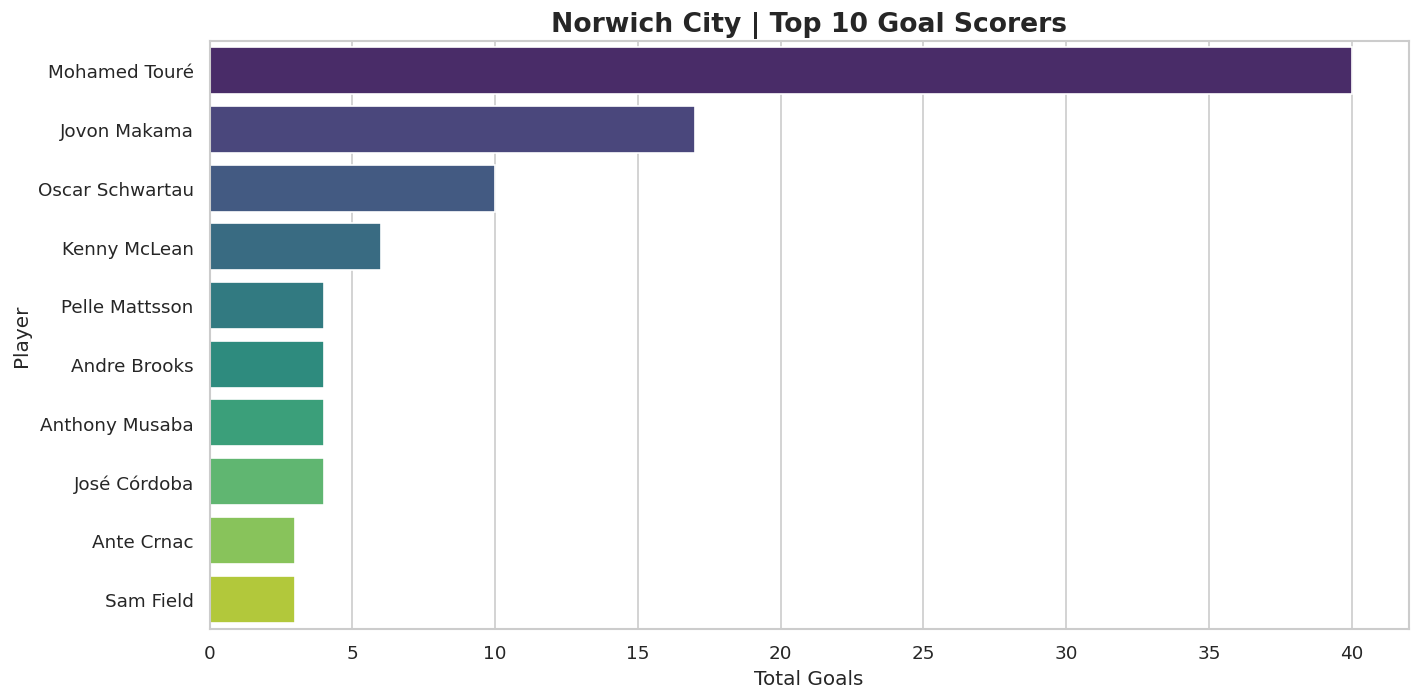

In [8]:
# ==========================================
# 07. ATTACKING PERFORMANCE
# ==========================================

top_scorers = df.nlargest(10, "goals")

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_scorers,
    x="goals",
    y="player_name",
    hue="player_name",
    palette="viridis",
    legend=False
)

plt.title(
    "Norwich City | Top 10 Goal Scorers",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Goals")
plt.ylabel("Player")

plt.tight_layout()
plt.show()

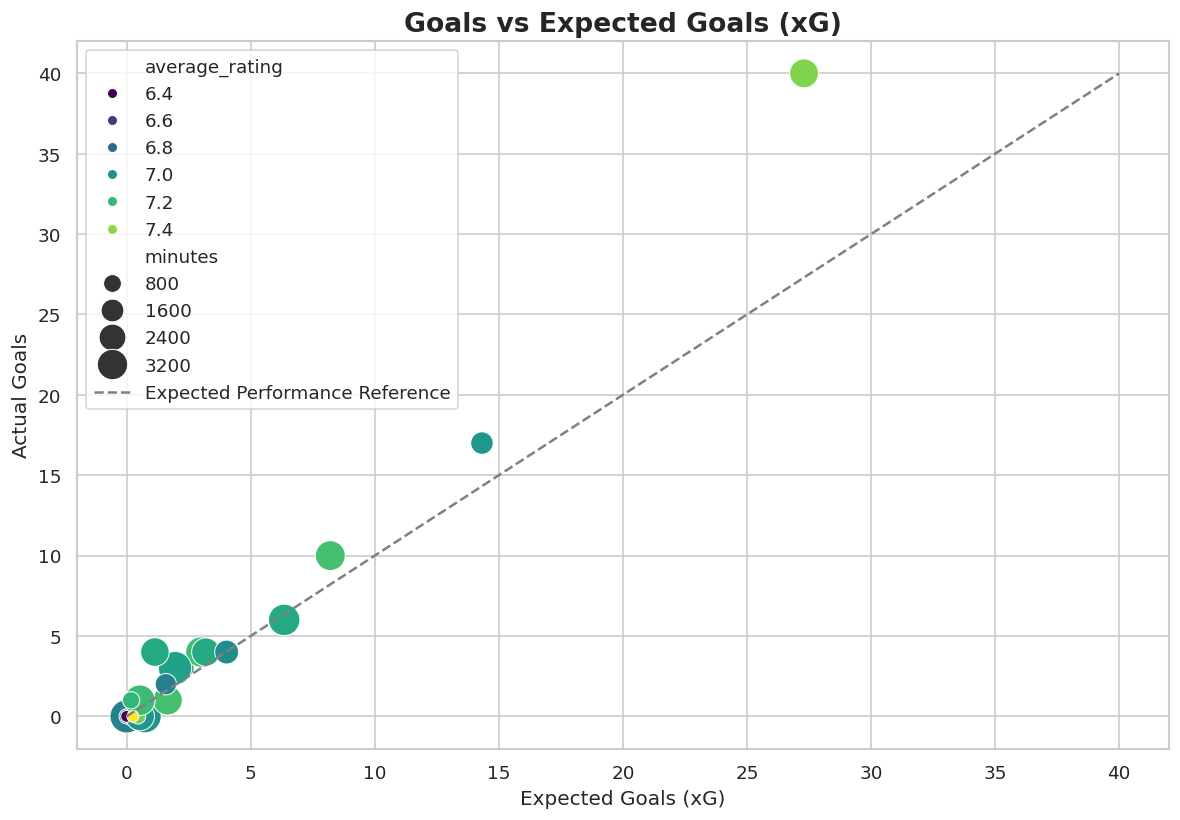

In [9]:
# ==========================================
# 08. FINISHING PERFORMANCE ANALYSIS
# ==========================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="expected_goals",
    y="goals",
    size="minutes",
    hue="average_rating",
    sizes=(50, 400),
    palette="viridis"
)

max_value = max(
    df["expected_goals"].max(),
    df["goals"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    color="gray",
    label="Expected Performance Reference"
)

plt.title(
    "Goals vs Expected Goals (xG)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Expected Goals (xG)")
plt.ylabel("Actual Goals")

plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# ==========================================
# 09. PLAYER PERFORMANCE RANKING
# ==========================================

ranking_columns = [
    "player_name",
    "minutes",
    "goals",
    "assists",
    "average_rating",
    "goals_per_90",
    "assists_per_90"
]

player_ranking = df[ranking_columns].copy()

# Apply a minimum playing-time threshold
eligible_players = player_ranking[
    player_ranking["minutes"] >= 900
].copy()

eligible_players = eligible_players.sort_values(
    by="average_rating",
    ascending=False
)

print("NORWICH CITY | PLAYER PERFORMANCE RANKING")

display(eligible_players.head(15))

NORWICH CITY | PLAYER PERFORMANCE RANKING


,player_name,minutes,goals,assists,average_rating,goals_per_90,assists_per_90
16,Mohamed Touré,2856,40,3,7.371053,1.260504,0.094538
22,Oscar Schwartau,3089,10,12,7.245946,0.291356,0.349628
18,Ben Chrisene,2996,1,9,7.244444,0.030040,0.270360
2,Pelle Mattsson,3186,4,2,7.230556,0.112994,0.056497
21,Kellen Fisher,3288,1,18,7.223684,0.027372,0.492701
19,José Córdoba,2790,4,0,7.129032,0.129032,0.000000
8,Andre Brooks,2727,4,14,7.127778,0.132013,0.462046
12,Kenny McLean,3475,6,7,7.125000,0.155396,0.181295
15,Ruairi McConville,3961,3,0,7.093182,0.068165,0.000000
1,Ante Crnac,951,3,3,7.064706,0.283912,0.283912


In [11]:
# ==========================================
# 10. EXTENDED PLAYER PERFORMANCE RANKING
# ==========================================

eligible_players = df[
    df["minutes"] >= 900
].copy()

eligible_players = eligible_players.sort_values(
    by="average_rating",
    ascending=False
)

eligible_players["performance_rank"] = range(
    1, len(eligible_players) + 1
)

ranking_output = eligible_players[
    [
        "performance_rank",
        "player_name",
        "minutes",
        "goals",
        "assists",
        "average_rating",
        "goals_per_90",
        "assists_per_90"
    ]
]

display(ranking_output.head(15))

,performance_rank,player_name,minutes,goals,assists,average_rating,goals_per_90,assists_per_90
16,1,Mohamed Touré,2856,40,3,7.371053,1.260504,0.094538
22,2,Oscar Schwartau,3089,10,12,7.245946,0.291356,0.349628
18,3,Ben Chrisene,2996,1,9,7.244444,0.030040,0.270360
2,4,Pelle Mattsson,3186,4,2,7.230556,0.112994,0.056497
21,5,Kellen Fisher,3288,1,18,7.223684,0.027372,0.492701
19,6,José Córdoba,2790,4,0,7.129032,0.129032,0.000000
8,7,Andre Brooks,2727,4,14,7.127778,0.132013,0.462046
12,8,Kenny McLean,3475,6,7,7.125000,0.155396,0.181295
15,9,Ruairi McConville,3961,3,0,7.093182,0.068165,0.000000
1,10,Ante Crnac,951,3,3,7.064706,0.283912,0.283912


Exploratory Data Analysis

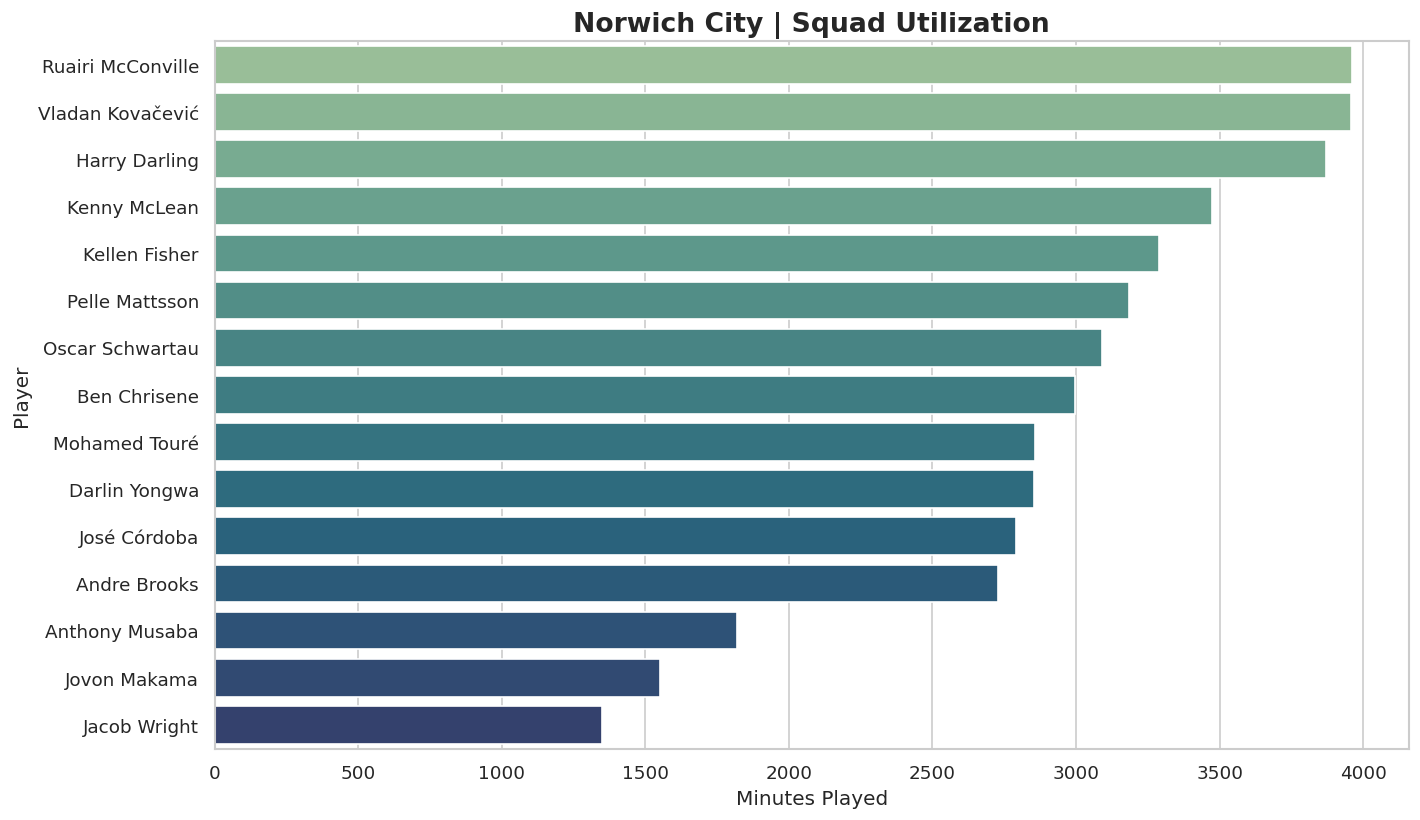

In [12]:
# ==========================================
# 01. SQUAD UTILIZATION ANALYSIS
# ==========================================

squad_utilization = df[
    ["player_name", "minutes", "starts", "substitute_appearances"]
].sort_values(
    by="minutes",
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=squad_utilization.head(15),
    x="minutes",
    y="player_name",
    hue="player_name",
    palette="crest",
    legend=False
)

plt.title(
    "Norwich City | Squad Utilization",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Minutes Played")
plt.ylabel("Player")

plt.tight_layout()
plt.show()

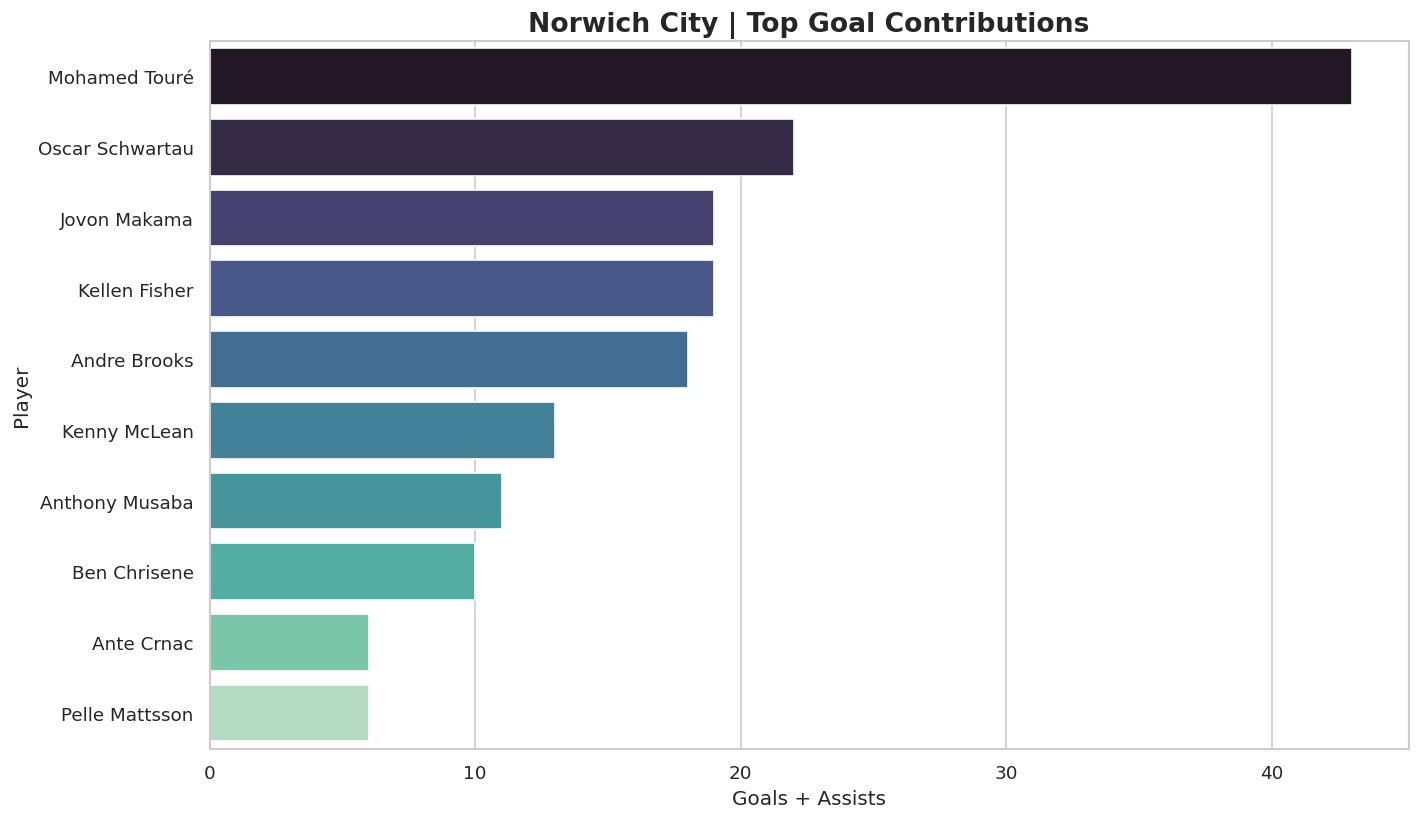

In [13]:
# ==========================================
# 02. ATTACKING CONTRIBUTION ANALYSIS
# ==========================================

df["goal_contributions"] = df["goals"] + df["assists"]

top_contributors = df.nlargest(
    10,
    "goal_contributions"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_contributors,
    x="goal_contributions",
    y="player_name",
    hue="player_name",
    palette="mako",
    legend=False
)

plt.title(
    "Norwich City | Top Goal Contributions",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Goals + Assists")
plt.ylabel("Player")

plt.tight_layout()
plt.show()

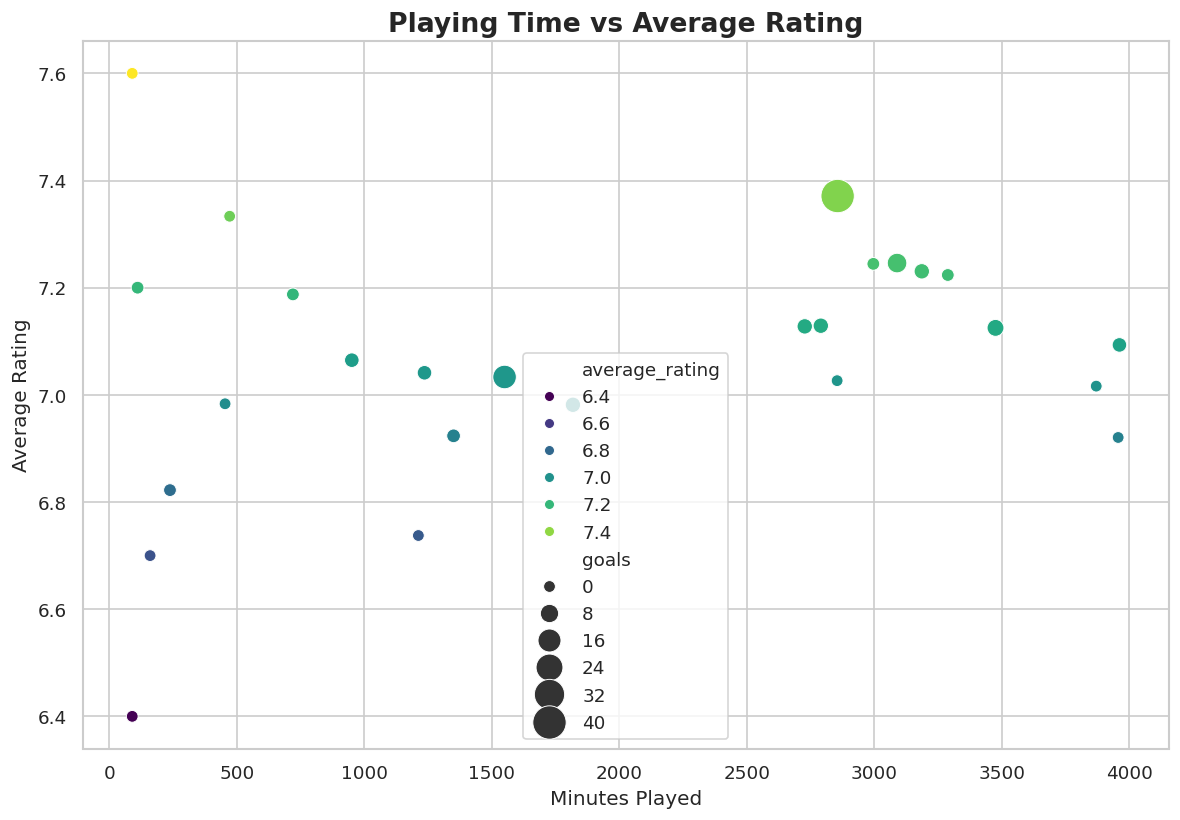

In [14]:
# ==========================================
# 03. PLAYING TIME VS PERFORMANCE
# ==========================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="minutes",
    y="average_rating",
    size="goals",
    hue="average_rating",
    palette="viridis",
    sizes=(50, 400)
)

plt.title(
    "Playing Time vs Average Rating",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Minutes Played")
plt.ylabel("Average Rating")

plt.tight_layout()
plt.show()

In [15]:
# ==========================================
# 04. FINISHING EFFICIENCY ANALYSIS
# ==========================================

df["goals_minus_xg"] = (
    df["goals"] - df["expected_goals"]
)

finishing_analysis = df[
    df["minutes"] >= 900
].sort_values(
    by="goals_minus_xg",
    ascending=False
)

display(
    finishing_analysis[
        [
            "player_name",
            "minutes",
            "goals",
            "expected_goals",
            "goals_minus_xg"
        ]
    ].head(15)
)

,player_name,minutes,goals,expected_goals,goals_minus_xg
16,Mohamed Touré,2856,40,27.30,12.70
19,José Córdoba,2790,4,1.14,2.86
17,Jovon Makama,1550,17,14.32,2.68
22,Oscar Schwartau,3089,10,8.21,1.79
6,Sam Field,1236,3,1.74,1.26
15,Ruairi McConville,3961,3,1.95,1.05
2,Pelle Mattsson,3186,4,2.99,1.01
8,Andre Brooks,2727,4,3.19,0.81
1,Ante Crnac,951,3,2.34,0.66
21,Kellen Fisher,3288,1,0.53,0.47


In [16]:
# Cell 05 — Exploratory Data Analysis: Key Findings

# Calculate key performance indicators
df["goal_contributions"] = df["goals"] + df["assists"]
df["goals_minus_xg"] = df["goals"] - df["expected_goals"]

# Identify key players
most_utilized = df.loc[df["minutes"].idxmax()]
highest_contributor = df.loc[df["goal_contributions"].idxmax()]
highest_overperformer = df.loc[df["goals_minus_xg"].idxmax()]

# Create key findings summary
key_findings = pd.DataFrame({
    "Analysis": [
        "Most Utilized Player",
        "Highest Goal Contribution",
        "Highest Goals - xG Difference"
    ],
    "Player": [
        most_utilized["player_name"],
        highest_contributor["player_name"],
        highest_overperformer["player_name"]
    ],
    "Result": [
        f'{most_utilized["minutes"]:.0f} minutes',
        f'{highest_contributor["goal_contributions"]:.0f} contributions',
        f'+{highest_overperformer["goals_minus_xg"]:.1f}'
    ]
})

display(key_findings)

,Analysis,Player,Result
0,Most Utilized Player,Ruairi McConville,3961 minutes
1,Highest Goal Contribution,Mohamed Touré,43 contributions
2,Highest Goals - xG Difference,Mohamed Touré,+12.7


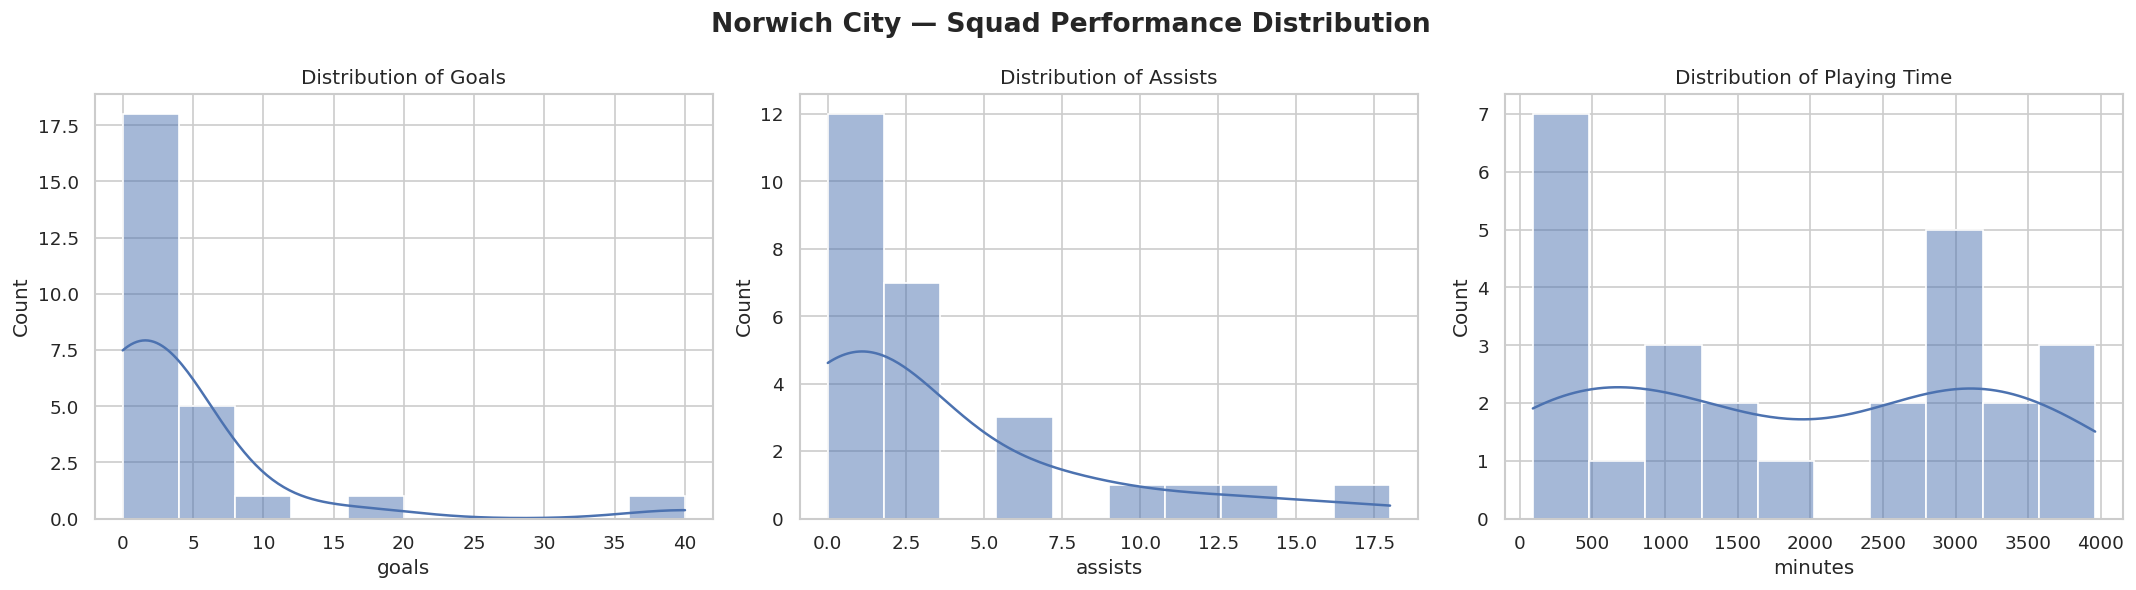

In [17]:
# Cell 06 — Squad Performance Distribution

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    data=df,
    x="goals",
    bins=10,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Goals")

sns.histplot(
    data=df,
    x="assists",
    bins=10,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution of Assists")

sns.histplot(
    data=df,
    x="minutes",
    bins=10,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Distribution of Playing Time")

plt.suptitle(
    "Norwich City — Squad Performance Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

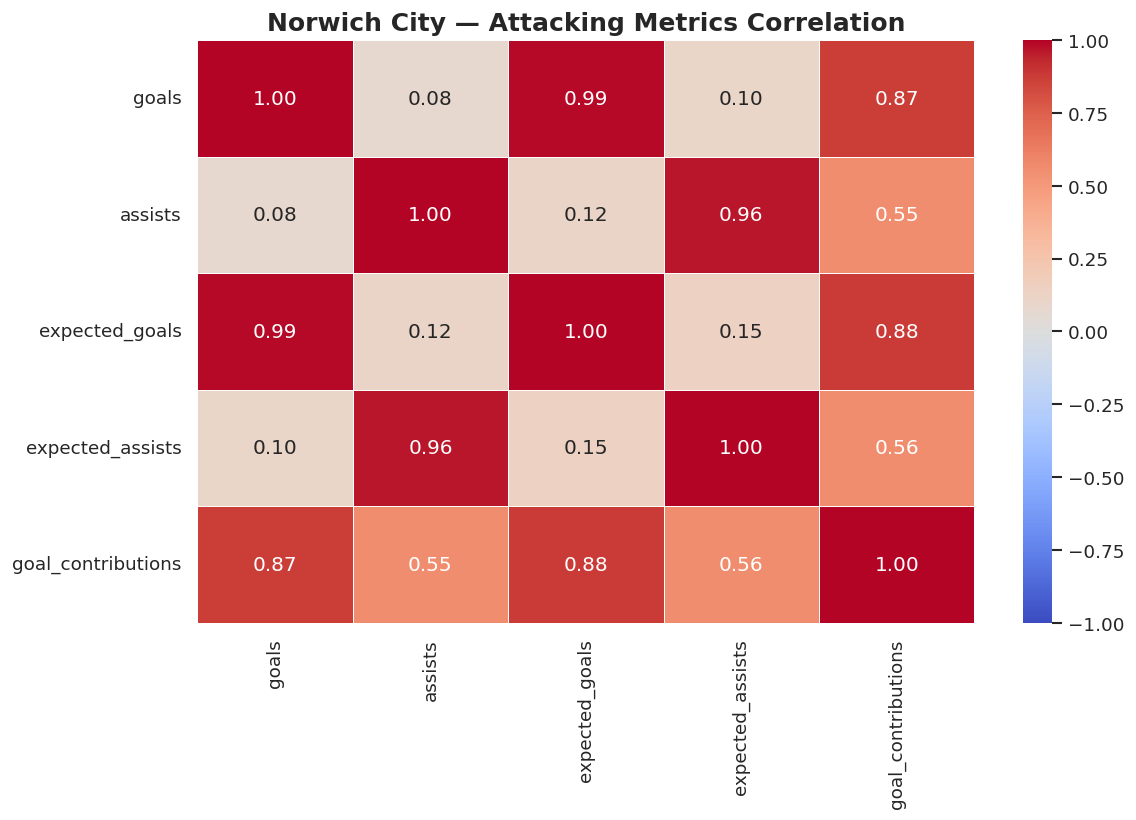

In [18]:
# Cell 07 — Attacking Performance Correlation

attacking_metrics = [
    "goals",
    "assists",
    "expected_goals",
    "expected_assists",
    "goal_contributions"
]

correlation_matrix = df[attacking_metrics].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title(
    "Norwich City — Attacking Metrics Correlation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [19]:
# Cell 08 — Top Attacking Performers

top_attacking_players = df[
    df["minutes"] >= 900
].copy()

top_attacking_players["goal_contributions"] = (
    top_attacking_players["goals"] +
    top_attacking_players["assists"]
)

top_attacking_players["goal_contributions_per_90"] = (
    top_attacking_players["goal_contributions"] /
    top_attacking_players["minutes"] * 90
)

top_attacking_players = top_attacking_players.sort_values(
    by="goal_contributions",
    ascending=False
)

display(
    top_attacking_players[
        [
            "player_name",
            "minutes",
            "goals",
            "assists",
            "goal_contributions",
            "goal_contributions_per_90",
            "average_rating"
        ]
    ].head(10)
)

,player_name,minutes,goals,assists,goal_contributions,goal_contributions_per_90,average_rating
16,Mohamed Touré,2856,40,3,43,1.355042,7.371053
22,Oscar Schwartau,3089,10,12,22,0.640984,7.245946
17,Jovon Makama,1550,17,2,19,1.103226,7.033333
21,Kellen Fisher,3288,1,18,19,0.520073,7.223684
8,Andre Brooks,2727,4,14,18,0.594059,7.127778
12,Kenny McLean,3475,6,7,13,0.336691,7.125000
10,Anthony Musaba,1818,4,7,11,0.544554,6.981481
18,Ben Chrisene,2996,1,9,10,0.300401,7.244444
2,Pelle Mattsson,3186,4,2,6,0.169492,7.230556
1,Ante Crnac,951,3,3,6,0.567823,7.064706


In [20]:

# Cell 09 — EDA Summary & Key Insights

# Calculate key performance metrics
df["goal_contributions"] = df["goals"] + df["assists"]

df["goal_contributions_per_90"] = np.where(
    df["minutes"] > 0,
    df["goal_contributions"] / df["minutes"] * 90,
    np.nan
)

df["goals_minus_xg"] = (
    df["goals"] - df["expected_goals"]
)

# Identify key players
most_utilized = df.loc[df["minutes"].idxmax()]

highest_contributor = df.loc[
    df["goal_contributions"].idxmax()
]

# Apply minimum playing time threshold
eligible_players = df[df["minutes"] >= 900].copy()

highest_efficiency = eligible_players.loc[
    eligible_players["goal_contributions_per_90"].idxmax()
]

highest_overperformer = df.loc[
    df["goals_minus_xg"].idxmax()
]

# Display analytical summary
print("NORWICH CITY — EDA KEY FINDINGS")
print("=" * 50)

print(
    f"Most Utilized Player: {most_utilized['player_name']} "
    f"({most_utilized['minutes']:.0f} minutes)"
)

print(
    f"Highest Goal Contributor: {highest_contributor['player_name']} "
    f"({highest_contributor['goal_contributions']:.0f} contributions)"
)

print(
    f"Highest Attacking Efficiency: {highest_efficiency['player_name']} "
    f"({highest_efficiency['goal_contributions_per_90']:.2f} per 90)"
)

print(
    f"Highest Goals - xG Difference: "
    f"{highest_overperformer['player_name']} "
    f"(+{highest_overperformer['goals_minus_xg']:.2f})"
)

print("\nAnalysis Criteria:")
print("- Minimum playing time for efficiency ranking: 900 minutes")
print("- Goal contributions = Goals + Assists")
print("- Attacking efficiency = Goal Contributions per 90 minutes")
print("- Goals - xG = Actual Goals minus Expected Goals")


NORWICH CITY — EDA KEY FINDINGS
Most Utilized Player: Ruairi McConville (3961 minutes)
Highest Goal Contributor: Mohamed Touré (43 contributions)
Highest Attacking Efficiency: Mohamed Touré (1.36 per 90)
Highest Goals - xG Difference: Mohamed Touré (+12.70)

Analysis Criteria:
- Minimum playing time for efficiency ranking: 900 minutes
- Goal contributions = Goals + Assists
- Attacking efficiency = Goal Contributions per 90 minutes
- Goals - xG = Actual Goals minus Expected Goals


## Exploratory Data Analysis — Key Findings

### 1. Squad Utilization
Ruairi McConville recorded the highest playing time in the Norwich City squad, with 3,961 minutes played. This indicates his significant involvement throughout the season.

### 2. Attacking Contribution
Mohamed Touré was Norwich City's highest goal contributor, recording 40 goals and 3 assists, resulting in 43 direct goal contributions.

### 3. Finishing Performance
Mohamed Touré recorded a positive Goals − xG difference of +12.7, scoring substantially more goals than his expected goals value.

### 4. Attacking Efficiency
Mohamed Touré's attacking output reached approximately 1.35 goal contributions per 90 minutes, highlighting his strong attacking productivity relative to playing time.

### 5. Overall Observation
The initial analysis suggests that Norwich City's attacking output was strongly influenced by Mohamed Touré, while Ruairi McConville played a major role in terms of squad utilization.

These findings provide an initial understanding of individual player performance and establish a foundation for more detailed squad and recruitment analysis.

# 03. Player Performance Analysis

This section evaluates individual player performances within Norwich City's squad.

The analysis focuses on:
- Individual attacking contributions.
- Goal and assist productivity.
- Performance efficiency per 90 minutes.
- Expected performance versus actual output.
- Identification of standout players.

A minimum playing time threshold of 900 minutes will be applied to relevant player comparisons to reduce the influence of limited playing time.

In [21]:
# 03.02 — Performance Metrics Preparation

# Calculate total attacking contributions
df["goal_contributions"] = df["goals"] + df["assists"]

# Calculate per-90-minute performance metrics
df["goals_per_90"] = np.where(
    df["minutes"] > 0,
    df["goals"] / df["minutes"] * 90,
    np.nan
)

df["assists_per_90"] = np.where(
    df["minutes"] > 0,
    df["assists"] / df["minutes"] * 90,
    np.nan
)

df["goal_contributions_per_90"] = np.where(
    df["minutes"] > 0,
    df["goal_contributions"] / df["minutes"] * 90,
    np.nan
)

# Calculate actual versus expected performance
df["goals_minus_xg"] = (
    df["goals"] - df["expected_goals"]
)

df["assists_minus_xa"] = (
    df["assists"] - df["expected_assists"]
)

print("Player performance metrics successfully prepared.")

display(
    df[
        [
            "player_name",
            "minutes",
            "goals",
            "assists",
            "goal_contributions",
            "goals_per_90",
            "assists_per_90",
            "goal_contributions_per_90",
            "goals_minus_xg"
        ]
    ].head(10)
)

Player performance metrics successfully prepared.


,player_name,minutes,goals,assists,goal_contributions,goals_per_90,assists_per_90,goal_contributions_per_90,goals_minus_xg
0,Vladan Kovačević,3956,0,0,0,0.000000,0.000000,0.000000,0.00
1,Ante Crnac,951,3,3,6,0.283912,0.283912,0.567823,0.66
2,Pelle Mattsson,3186,4,2,6,0.112994,0.056497,0.169492,1.01
3,Mathias Kvistgaarden,238,1,2,3,0.378151,0.756303,1.134454,0.16
4,Jack Stacey,1212,0,1,1,0.000000,0.074257,0.074257,-0.28
5,Daniel Grimshaw,454,0,0,0,0.000000,0.000000,0.000000,0.00
6,Sam Field,1236,3,0,3,0.218447,0.000000,0.218447,1.26
7,Paris Maghoma,160,0,0,0,0.000000,0.000000,0.000000,-0.54
8,Andre Brooks,2727,4,14,18,0.132013,0.462046,0.594059,0.81
9,Harry Darling,3870,0,0,0,0.000000,0.000000,0.000000,-0.73


In [22]:
# 03.03 — Attacking Performance Ranking

minimum_minutes = 900

eligible_players = df[
    df["minutes"] >= minimum_minutes
].copy()

attacking_ranking = eligible_players.sort_values(
    by="goal_contributions",
    ascending=False
)

attacking_ranking = attacking_ranking[
    [
        "player_name",
        "minutes",
        "goals",
        "assists",
        "goal_contributions",
        "average_rating"
    ]
]

attacking_ranking.insert(
    0,
    "rank",
    range(1, len(attacking_ranking) + 1)
)

display(attacking_ranking.head(15))

,rank,player_name,minutes,goals,assists,goal_contributions,average_rating
16,1,Mohamed Touré,2856,40,3,43,7.371053
22,2,Oscar Schwartau,3089,10,12,22,7.245946
17,3,Jovon Makama,1550,17,2,19,7.033333
21,4,Kellen Fisher,3288,1,18,19,7.223684
8,5,Andre Brooks,2727,4,14,18,7.127778
12,6,Kenny McLean,3475,6,7,13,7.125000
10,7,Anthony Musaba,1818,4,7,11,6.981481
18,8,Ben Chrisene,2996,1,9,10,7.244444
2,9,Pelle Mattsson,3186,4,2,6,7.230556
1,10,Ante Crnac,951,3,3,6,7.064706


In [23]:
# 03.04 — Attacking Efficiency Ranking

efficiency_ranking = eligible_players.sort_values(
    by="goal_contributions_per_90",
    ascending=False
)

efficiency_ranking = efficiency_ranking[
    [
        "player_name",
        "minutes",
        "goals",
        "assists",
        "goal_contributions",
        "goal_contributions_per_90"
    ]
].copy()

efficiency_ranking.insert(
    0,
    "rank",
    range(1, len(efficiency_ranking) + 1)
)

display(efficiency_ranking.head(15))

,rank,player_name,minutes,goals,assists,goal_contributions,goal_contributions_per_90
16,1,Mohamed Touré,2856,40,3,43,1.355042
17,2,Jovon Makama,1550,17,2,19,1.103226
22,3,Oscar Schwartau,3089,10,12,22,0.640984
8,4,Andre Brooks,2727,4,14,18,0.594059
1,5,Ante Crnac,951,3,3,6,0.567823
10,6,Anthony Musaba,1818,4,7,11,0.544554
21,7,Kellen Fisher,3288,1,18,19,0.520073
12,8,Kenny McLean,3475,6,7,13,0.336691
18,9,Ben Chrisene,2996,1,9,10,0.300401
24,10,Jacob Wright,1350,2,2,4,0.266667


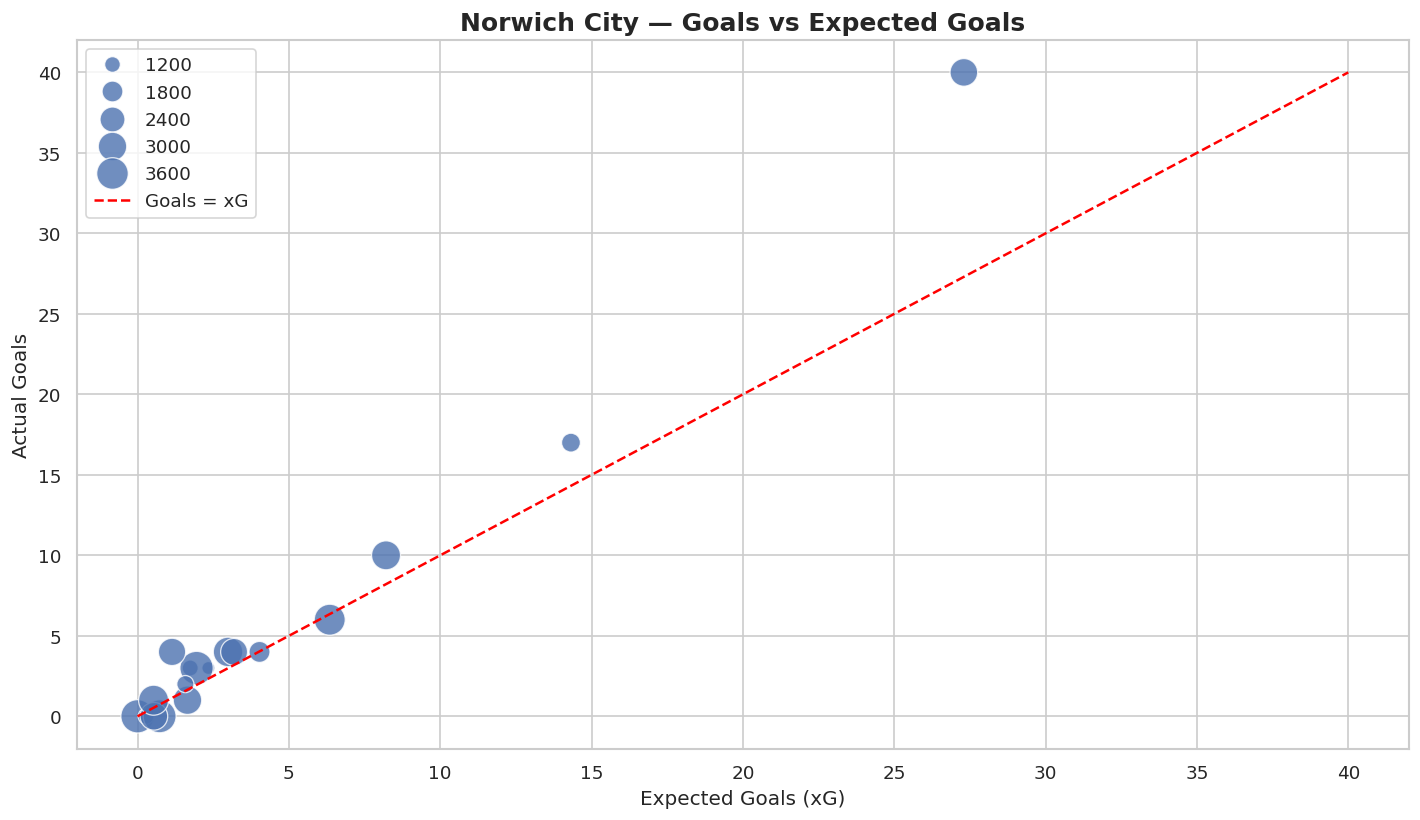

In [24]:
# 03.05 — Goals vs Expected Goals Analysis

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=eligible_players,
    x="expected_goals",
    y="goals",
    size="minutes",
    sizes=(60, 400),
    alpha=0.8
)

# Add reference line (Goals = xG)
max_value = max(
    eligible_players["expected_goals"].max(),
    eligible_players["goals"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    color="red",
    label="Goals = xG"
)

plt.title(
    "Norwich City — Goals vs Expected Goals",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Expected Goals (xG)")
plt.ylabel("Actual Goals")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# 03.06 — Goals vs xG Performance Ranking

finishing_ranking = eligible_players[
    [
        "player_name",
        "minutes",
        "goals",
        "expected_goals",
        "goals_minus_xg"
    ]
].copy()

finishing_ranking = finishing_ranking.sort_values(
    by="goals_minus_xg",
    ascending=False
)

display(finishing_ranking.head(15))

,player_name,minutes,goals,expected_goals,goals_minus_xg
16,Mohamed Touré,2856,40,27.30,12.70
19,José Córdoba,2790,4,1.14,2.86
17,Jovon Makama,1550,17,14.32,2.68
22,Oscar Schwartau,3089,10,8.21,1.79
6,Sam Field,1236,3,1.74,1.26
15,Ruairi McConville,3961,3,1.95,1.05
2,Pelle Mattsson,3186,4,2.99,1.01
8,Andre Brooks,2727,4,3.19,0.81
1,Ante Crnac,951,3,2.34,0.66
21,Kellen Fisher,3288,1,0.53,0.47


In [26]:
# 03.07 — Player Performance Comparison

comparison_metrics = eligible_players[
    [
        "player_name",
        "minutes",
        "goals",
        "assists",
        "expected_goals",
        "expected_assists",
        "goal_contributions_per_90",
        "average_rating"
    ]
].copy()

display(
    comparison_metrics.sort_values(
        by="goal_contributions_per_90",
        ascending=False
    ).head(15).round(2)
)

,player_name,minutes,goals,assists,expected_goals,expected_assists,goal_contributions_per_90,average_rating
16,Mohamed Touré,2856,40,3,27.30,2.47,1.36,7.37
17,Jovon Makama,1550,17,2,14.32,1.39,1.10,7.03
22,Oscar Schwartau,3089,10,12,8.21,9.57,0.64,7.25
8,Andre Brooks,2727,4,14,3.19,10.83,0.59,7.13
1,Ante Crnac,951,3,3,2.34,3.41,0.57,7.06
10,Anthony Musaba,1818,4,7,4.03,5.80,0.54,6.98
21,Kellen Fisher,3288,1,18,0.53,10.35,0.52,7.22
12,Kenny McLean,3475,6,7,6.35,5.21,0.34,7.12
18,Ben Chrisene,2996,1,9,1.65,8.31,0.30,7.24
24,Jacob Wright,1350,2,2,1.58,2.05,0.27,6.92


In [27]:
# 03.08 — Performance Leaders Comparison

metrics_to_compare = {
    "Goal Contributions": "goal_contributions",
    "Goal Contributions per 90": "goal_contributions_per_90",
    "Average Rating": "average_rating",
    "Goals - xG": "goals_minus_xg"
}

performance_leaders = []

for metric_name, column in metrics_to_compare.items():

    leader = eligible_players.loc[
        eligible_players[column].idxmax()
    ]

    performance_leaders.append({
        "Metric": metric_name,
        "Player": leader["player_name"],
        "Value": round(leader[column], 2)
    })

performance_leaders = pd.DataFrame(performance_leaders)

display(performance_leaders)

,Metric,Player,Value
0,Goal Contributions,Mohamed Touré,43.00
1,Goal Contributions per 90,Mohamed Touré,1.36
2,Average Rating,Mohamed Touré,7.37
3,Goals - xG,Mohamed Touré,12.70


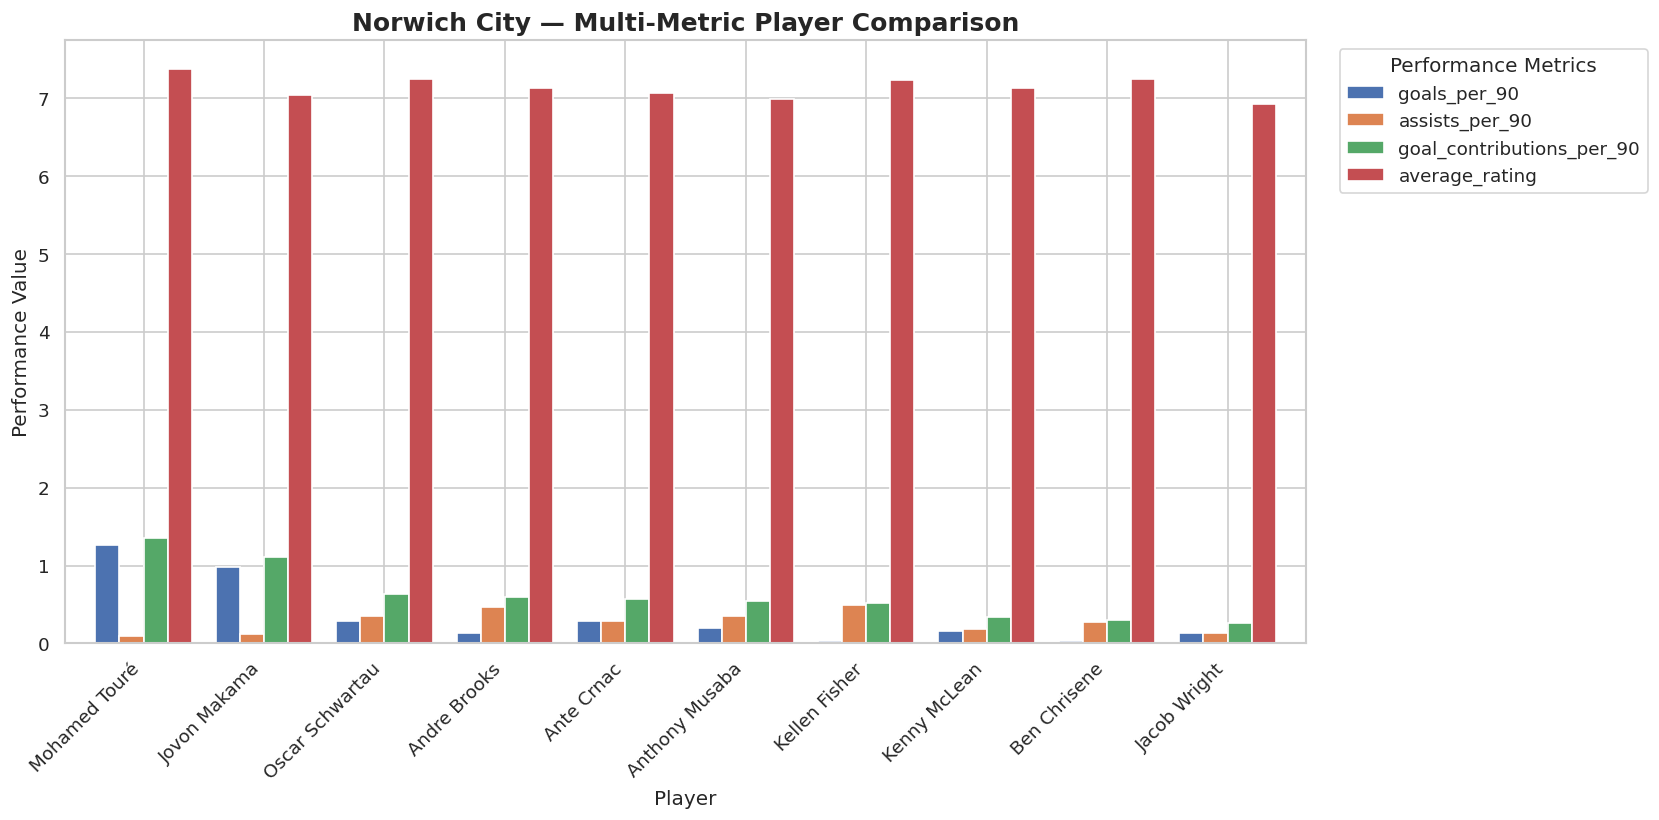

In [28]:
# 03.09 — Multi-Metric Player Comparison

comparison_data = eligible_players[
    [
        "player_name",
        "goals_per_90",
        "assists_per_90",
        "goal_contributions_per_90",
        "average_rating"
    ]
].copy()

comparison_data = comparison_data.sort_values(
    by="goal_contributions_per_90",
    ascending=False
).head(10)

comparison_data = comparison_data.set_index("player_name")

comparison_data.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title(
    "Norwich City — Multi-Metric Player Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Player")
plt.ylabel("Performance Value")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Performance Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

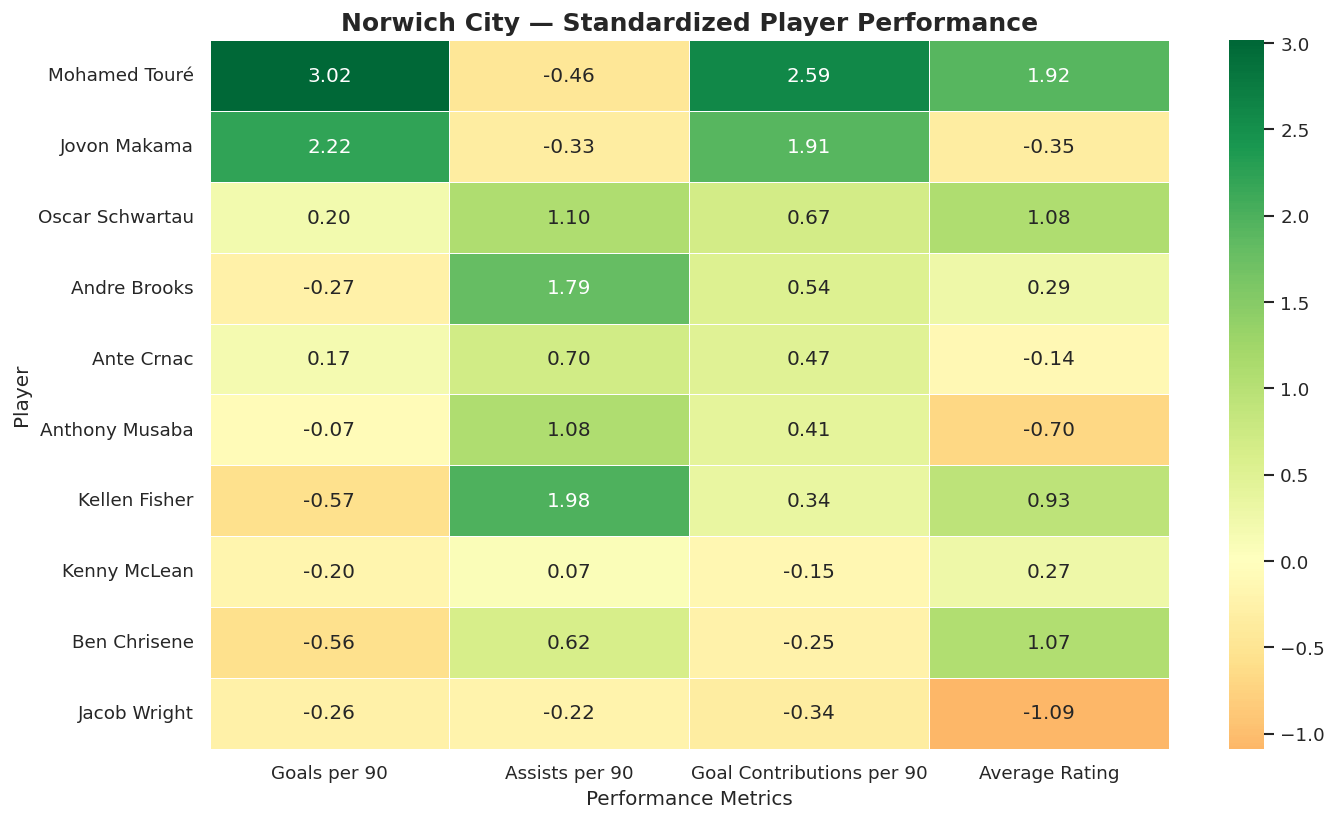

In [29]:
# 03.10 — Standardized Player Performance Comparison

metrics = [
    "goals_per_90",
    "assists_per_90",
    "goal_contributions_per_90",
    "average_rating"
]

# Select the top 10 players based on goal contributions per 90
standardized_data = eligible_players[
    ["player_name"] + metrics
].sort_values(
    by="goal_contributions_per_90",
    ascending=False
).head(10).copy()

# Apply Z-score standardization
for metric in metrics:
    standardized_data[f"{metric}_zscore"] = (
        standardized_data[metric] - eligible_players[metric].mean()
    ) / eligible_players[metric].std()

# Prepare the heatmap data
heatmap_data = standardized_data.set_index("player_name")[
    [f"{metric}_zscore" for metric in metrics]
]

heatmap_data.columns = [
    "Goals per 90",
    "Assists per 90",
    "Goal Contributions per 90",
    "Average Rating"
]

# Visualize standardized performance
plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5
)

plt.title(
    "Norwich City — Standardized Player Performance",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Performance Metrics")
plt.ylabel("Player")

plt.tight_layout()
plt.show()

In [30]:
# 03.11 — Player Performance Summary

# Identify the best player for each performance metric
summary_metrics = {
    "Most Goal Contributions": "goal_contributions",
    "Best Goal Contribution Rate": "goal_contributions_per_90",
    "Best Average Rating": "average_rating",
    "Best Finishing Performance": "goals_minus_xg",
    "Best Assist Rate": "assists_per_90"
}

summary_results = []

for label, metric in summary_metrics.items():

    leader = eligible_players.loc[
        eligible_players[metric].idxmax()
    ]

    summary_results.append({
        "Performance Category": label,
        "Player": leader["player_name"],
        "Value": round(leader[metric], 2)
    })

player_performance_summary = pd.DataFrame(summary_results)

display(player_performance_summary)

,Performance Category,Player,Value
0,Most Goal Contributions,Mohamed Touré,43.00
1,Best Goal Contribution Rate,Mohamed Touré,1.36
2,Best Average Rating,Mohamed Touré,7.37
3,Best Finishing Performance,Mohamed Touré,12.70
4,Best Assist Rate,Kellen Fisher,0.49


## 03.12 — Player Performance Key Findings

### Key Findings

- Mohamed Touré emerged as the standout attacking performer based on total goal contributions.
- He also recorded the highest goal contribution rate per 90 minutes among eligible players.
- His average rating was the highest in the squad, indicating consistently strong match performances.
- His actual goals significantly exceeded his expected goals, suggesting strong finishing output during the season.
- Player performance varied across different attacking metrics, highlighting the importance of evaluating players through multiple indicators rather than relying on goals alone.

### Analytical Conclusion

The analysis identifies Mohamed Touré as Norwich City's most influential attacking player during the analyzed season.

However, evaluating player performance requires considering playing time, attacking efficiency, expected statistics, and overall match ratings together.

All findings are based on Football Manager 2027 save data and should not be interpreted as official real-world football performance statistics.

# 04. Squad Analysis

This section evaluates the overall squad structure of Norwich City using player profile data.

The analysis focuses on:

- Squad age distribution.
- Current Ability (CA) and Potential Ability (PA).
- Player positional distribution.
- Squad development and long-term potential.
- Identifying possible squad depth and recruitment needs.

The objective is to understand the squad's current structure and identify potential areas for improvement.

In [31]:
# 04.02 — Squad Data Preparation

# Display available squad profile columns
profile_keywords = [
    "age",
    "ability",
    "potential",
    "position",
    "value",
    "wage",
    "contract"
]

profile_columns = [
    column for column in df.columns
    if any(keyword in column.lower() for keyword in profile_keywords)
]

print("Available squad profile columns:")

for column in profile_columns:
    print(column)

print("\nDataset shape:", df.shape)

Available squad profile columns:
average_rating
age
ability_current
ability_potential
ability_potential_range_code
natural_positions
accomplished_positions
transfer_value
contract_wage
contract_end
contract_squad_status
contract_on_loan

Dataset shape: (26, 57)


Squad Age Statistics:


,Age
count,26.000000
mean,24.730769
std,3.550298
min,20.000000
25%,22.250000
50%,24.000000
75%,26.000000
max,35.000000


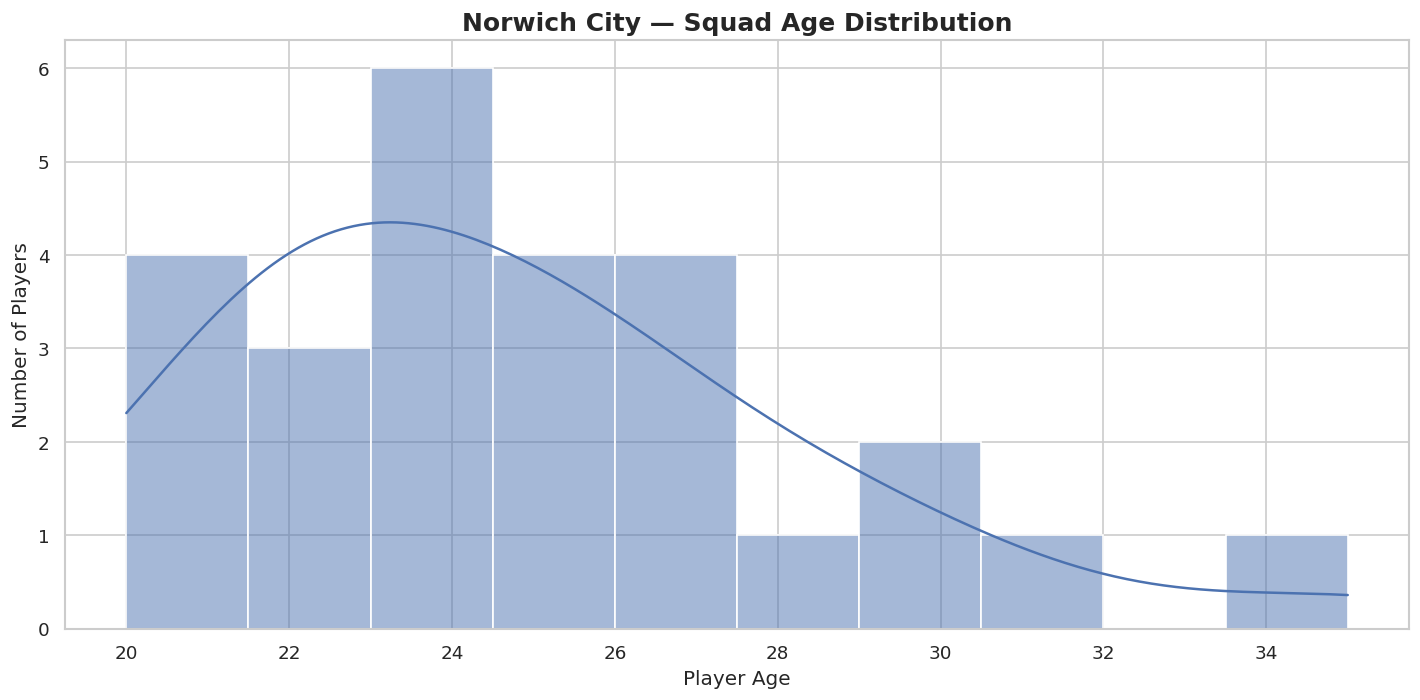

In [32]:
# 04.03 — Squad Age Distribution

# Ensure age values are numeric
df["age"] = pd.to_numeric(df["age"], errors="coerce")

# Calculate age statistics
age_summary = df["age"].describe()

print("Squad Age Statistics:")
display(age_summary.to_frame(name="Age"))

# Visualize age distribution
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="age",
    bins=10,
    kde=True
)

plt.title(
    "Norwich City — Squad Age Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Player Age")
plt.ylabel("Number of Players")

plt.tight_layout()
plt.show()

,Age Group,Number of Players
0,U21,2
1,21-24,11
2,25-28,9
3,29+,4


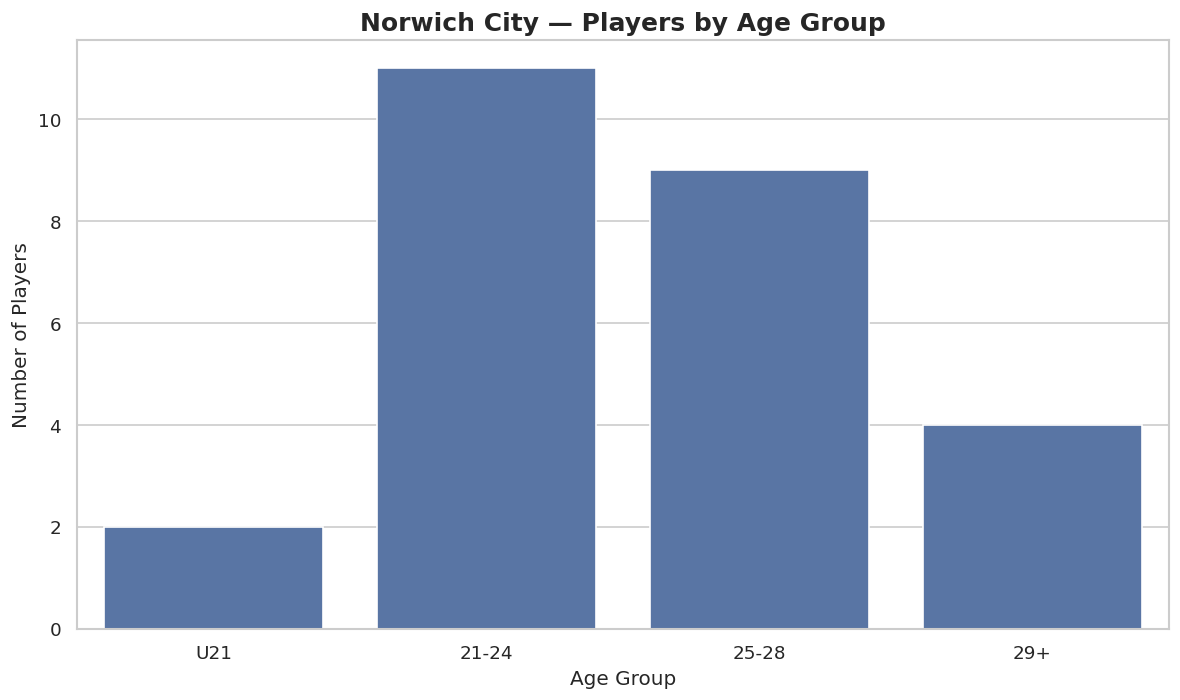

In [33]:
# 04.04 — Age Group Classification

# Define age categories
age_bins = [0, 21, 25, 29, 100]

age_labels = [
    "U21",
    "21-24",
    "25-28",
    "29+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Count players in each age group
age_group_summary = (
    df["age_group"]
    .value_counts()
    .reindex(age_labels, fill_value=0)
    .reset_index()
)

age_group_summary.columns = [
    "Age Group",
    "Number of Players"
]

display(age_group_summary)

# Visualize age group distribution
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_group_summary,
    x="Age Group",
    y="Number of Players"
)

plt.title(
    "Norwich City — Players by Age Group",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Age Group")
plt.ylabel("Number of Players")

plt.tight_layout()
plt.show()

In [34]:
# 04.05 — Current Ability vs Potential Ability

# Convert ability columns to numeric
ability_columns = [
    "ability_current",
    "ability_potential"
]

for column in ability_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Calculate potential development gap
df["ability_gap"] = (
    df["ability_potential"] - df["ability_current"]
)

# Display player ability profiles
ability_analysis = df[
    [
        "player_name",
        "age",
        "ability_current",
        "ability_potential",
        "ability_gap"
    ]
].sort_values(
    by="ability_current",
    ascending=False
)

display(ability_analysis.head(15))

,player_name,age,ability_current,ability_potential,ability_gap
2,Pelle Mattsson,25,132,148,16
16,Mohamed Touré,23,131,145,14
15,Ruairi McConville,22,129,150,21
22,Oscar Schwartau,20,129,150,21
8,Andre Brooks,23,128,135,7
21,Kellen Fisher,22,127,150,23
17,Jovon Makama,23,124,145,21
19,José Córdoba,25,123,145,22
7,Paris Maghoma,25,122,140,18
11,Darlin Yongwa,26,122,134,12


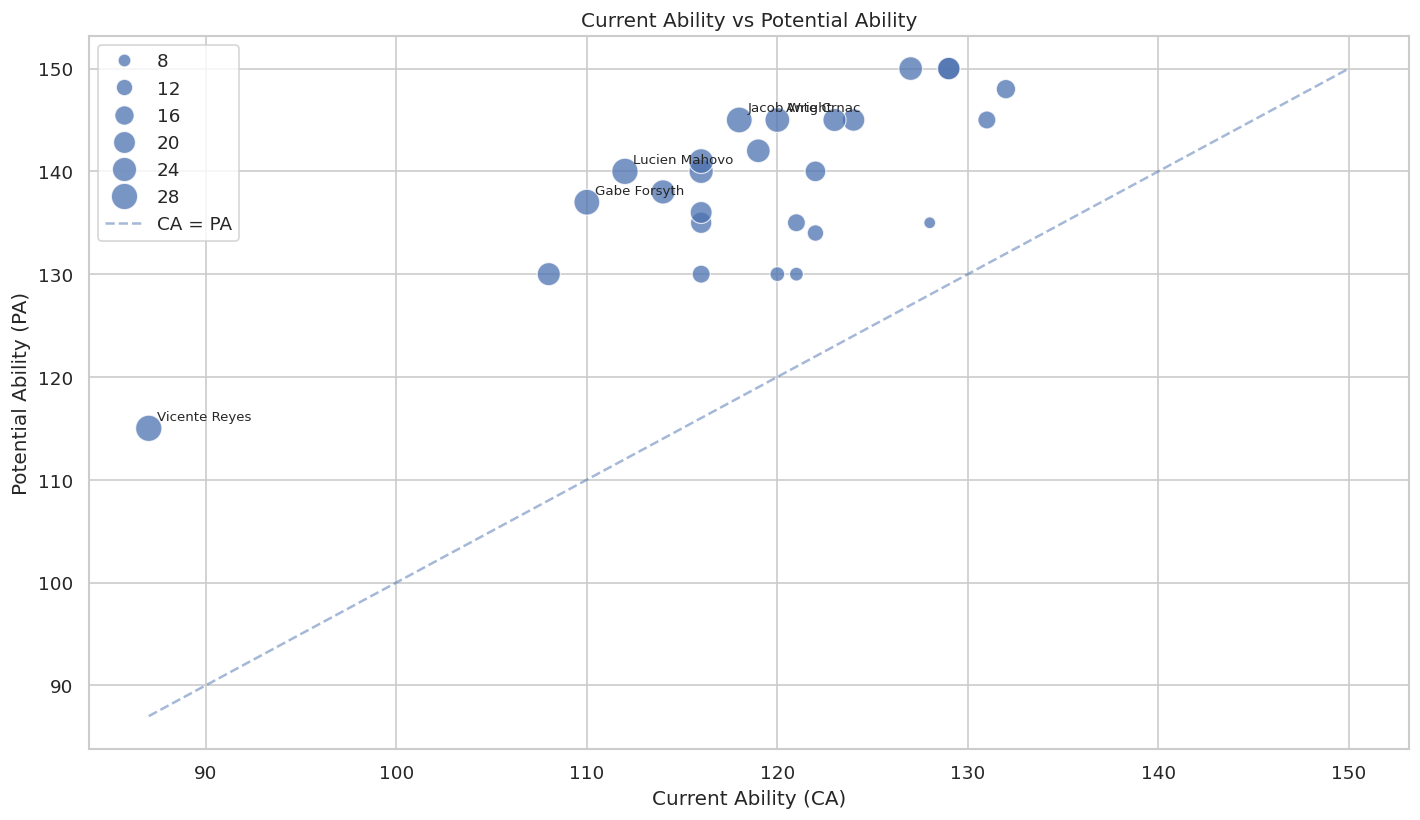

Players with the largest development gaps:


,player_name,age,ability_current,ability_potential,ability_gap
14,Vicente Reyes,23,87,115,28
25,Lucien Mahovo,21,112,140,28
23,Gabe Forsyth,20,110,137,27
24,Jacob Wright,21,118,145,27
1,Ante Crnac,23,120,145,25


In [35]:

# 04.06 — Current Ability vs Potential Ability Visualization

# Filter valid ability records
valid_ability = df[
    (df["ability_current"] > 0) &
    (df["ability_potential"] > 0)
].copy()

# Calculate ability gap
valid_ability["ability_gap"] = (
    valid_ability["ability_potential"] -
    valid_ability["ability_current"]
)

# Identify players with the largest development gaps
top_gap_players = valid_ability.nlargest(5, "ability_gap")

# Create scatter plot
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=valid_ability,
    x="ability_current",
    y="ability_potential",
    size="ability_gap",
    sizes=(50, 250),
    alpha=0.75
)

# Add player labels for the five largest gaps
for _, player in top_gap_players.iterrows():
    plt.annotate(
        player["player_name"],
        (player["ability_current"], player["ability_potential"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Add reference line
min_value = min(
    valid_ability["ability_current"].min(),
    valid_ability["ability_potential"].min()
)

max_value = max(
    valid_ability["ability_current"].max(),
    valid_ability["ability_potential"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    alpha=0.5,
    label="CA = PA"
)

plt.title("Current Ability vs Potential Ability")
plt.xlabel("Current Ability (CA)")
plt.ylabel("Potential Ability (PA)")
plt.legend()
plt.tight_layout()
plt.show()

print("Players with the largest development gaps:")
display(
    top_gap_players[
        ["player_name", "age", "ability_current",
         "ability_potential", "ability_gap"]
    ]
)


In [36]:
# 04.07 — Natural Position Distribution

# Inspect natural position values
print("Sample natural position data:")
display(
    df[["player_name", "natural_positions"]].head(15)
)

print("\nUnique natural position values:")
print(df["natural_positions"].value_counts().head(20))


Sample natural position data:


,player_name,natural_positions
0,Vladan Kovačević,GK
1,Ante Crnac,AMR;STC
2,Pelle Mattsson,DM;MC
3,Mathias Kvistgaarden,STC
4,Jack Stacey,DR
5,Daniel Grimshaw,GK
6,Sam Field,DM;MC
7,Paris Maghoma,AMC
8,Andre Brooks,MC;AMR
9,Harry Darling,DC



Unique natural position values:
natural_positions
DM;MC      5
GK         3
STC        3
DC         3
DL         2
AMR;STC    1
DR         1
MC;AMR     1
AMC        1
AML;AMR    1
DL;WBL     1
AML        1
DR;WBR     1
AML;AMC    1
MC         1
Name: count, dtype: int64


Natural Position Distribution:


,Position,Player Count
0,MC,7
1,DM,5
2,STC,4
3,AMR,3
4,GK,3
5,DC,3
6,DL,3
7,AML,3
8,AMC,2
9,DR,2


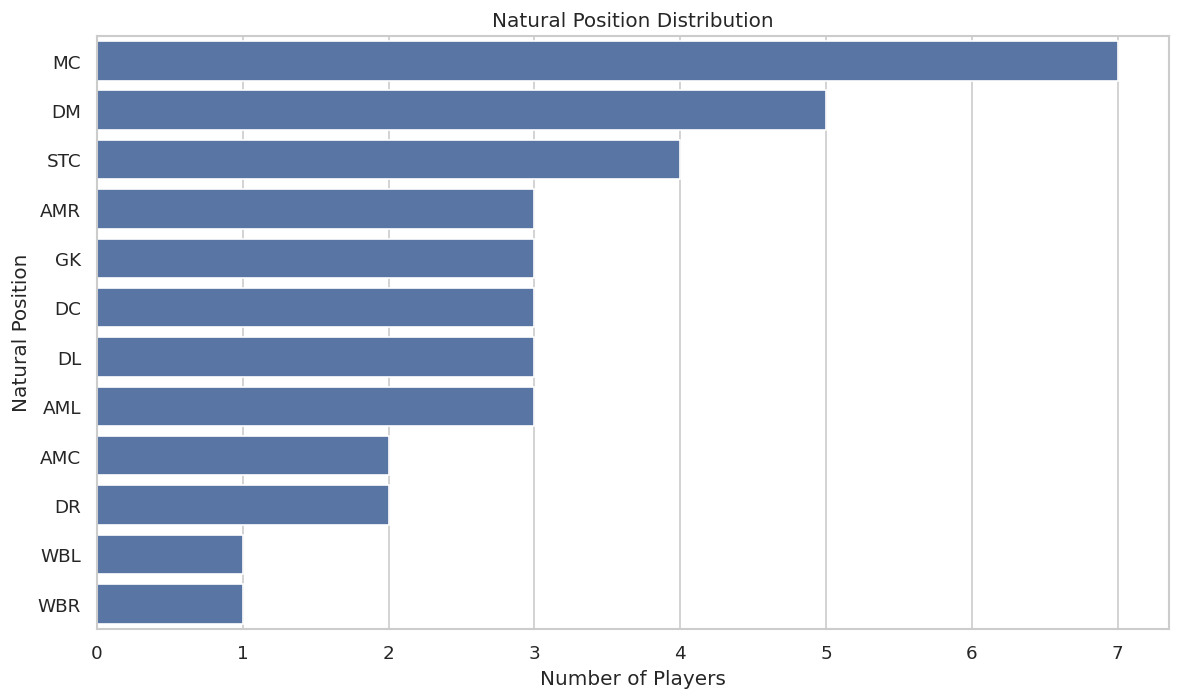

Total player-position records: 37
Unique players: 26


In [37]:

# 04.08 — Natural Position Distribution Analysis

# Split multiple positions into separate records
position_data = (
    df[["player_name", "natural_positions"]]
    .dropna(subset=["natural_positions"])
    .assign(
        natural_positions=lambda x:
        x["natural_positions"].str.split(";")
    )
    .explode("natural_positions")
)

# Clean position labels
position_data["natural_positions"] = (
    position_data["natural_positions"].str.strip()
)

# Count players for each natural position
position_summary = (
    position_data["natural_positions"]
    .value_counts()
    .reset_index()
)

position_summary.columns = ["Position", "Player Count"]

# Display position distribution
print("Natural Position Distribution:")
display(position_summary)

# Visualize position distribution
plt.figure(figsize=(10, 6))

sns.barplot(
    data=position_summary,
    x="Player Count",
    y="Position"
)

plt.title("Natural Position Distribution")
plt.xlabel("Number of Players")
plt.ylabel("Natural Position")
plt.tight_layout()
plt.show()

print("Total player-position records:", len(position_data))
print("Unique players:", position_data["player_name"].nunique())


,Position Group,Position Records
0,Goalkeeper,3
1,Defence,10
2,Midfield,14
3,Attack,10


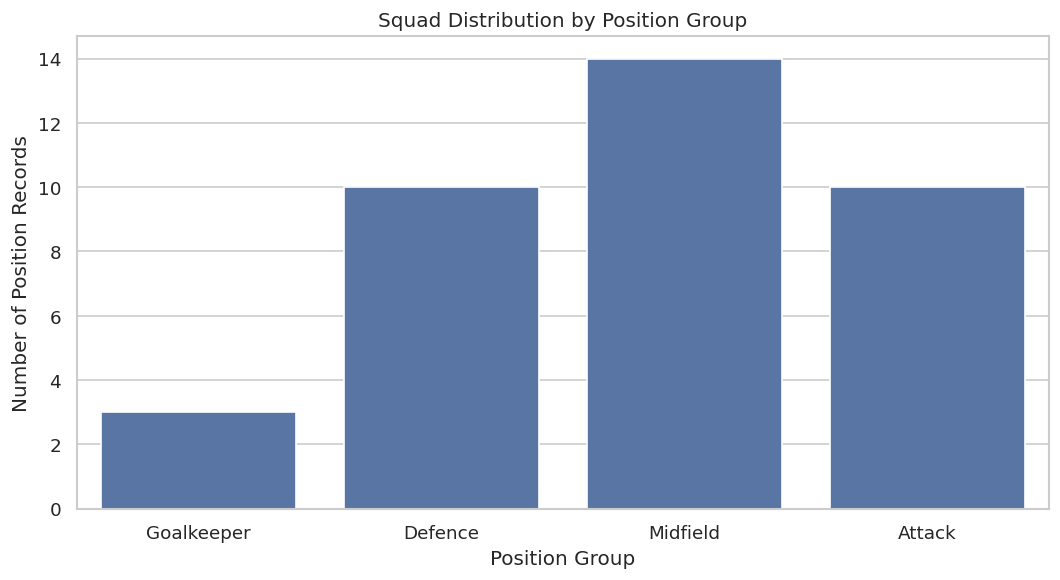

In [38]:

# 04.09 — Position Group Analysis

# Define position groups
position_groups = {
    "Goalkeeper": ["GK"],
    "Defence": ["DC", "DL", "DR", "WBL", "WBR"],
    "Midfield": ["DM", "MC", "AMC"],
    "Attack": ["AML", "AMR", "STC"]
}

# Map individual positions to broader groups
position_data["position_group"] = position_data[
    "natural_positions"
].map({
    position: group
    for group, positions in position_groups.items()
    for position in positions
})

# Count player-position records by group
group_summary = (
    position_data["position_group"]
    .value_counts()
    .reindex(position_groups.keys(), fill_value=0)
    .reset_index()
)

group_summary.columns = ["Position Group", "Position Records"]

# Display results
display(group_summary)

# Visualize position groups
plt.figure(figsize=(9, 5))

sns.barplot(
    data=group_summary,
    x="Position Group",
    y="Position Records"
)

plt.title("Squad Distribution by Position Group")
plt.xlabel("Position Group")
plt.ylabel("Number of Position Records")
plt.tight_layout()
plt.show()


In [39]:

# 04.10 — Contract and Squad Status Analysis

# Select contract-related columns
contract_columns = [
    "player_name",
    "age",
    "contract_squad_status",
    "contract_end",
    "contract_on_loan",
    "transfer_value",
    "contract_wage"
]

# Display contract information
contract_analysis = df[contract_columns].copy()

print("Contract and Squad Status Overview:")
display(contract_analysis.sort_values("contract_end"))

# Count squad status categories
print("\nSquad Status Distribution:")
display(
    df["contract_squad_status"]
    .fillna("Unknown")
    .value_counts()
    .rename_axis("Squad Status")
    .reset_index(name="Player Count")
)

# Count loan status
print("\nLoan Status Distribution:")
display(
    df["contract_on_loan"]
    .fillna(False)
    .value_counts()
    .rename_axis("On Loan")
    .reset_index(name="Player Count")
)


Contract and Squad Status Overview:


,player_name,age,contract_squad_status,contract_end,contract_on_loan,transfer_value,contract_wage
14,Vicente Reyes,23,backup,2027-06-30,False,13618,3000
4,Jack Stacey,31,squad_player,2027-06-30,False,484254,25000
12,Kenny McLean,35,regular_starter,2028-06-30,False,1329853,25000
23,Gabe Forsyth,20,breakthrough_prospect,2028-06-30,False,2674329,5000
21,Kellen Fisher,22,regular_starter,2028-06-30,False,15716895,10000
9,Harry Darling,27,squad_player,2028-06-30,False,6014257,16000
25,Lucien Mahovo,21,squad_player,2028-06-30,False,4865634,5000
1,Ante Crnac,23,squad_player,2028-06-30,False,9930201,12000
5,Daniel Grimshaw,29,cup_goalkeeper,2028-06-30,False,610795,9000
7,Paris Maghoma,25,regular_starter,2029-06-30,False,5886000,10000



Squad Status Distribution:


,Squad Status,Player Count
0,squad_player,8
1,important_player,7
2,regular_starter,6
3,cup_goalkeeper,1
4,fringe_player,1
5,backup,1
6,star_player,1
7,breakthrough_prospect,1



Loan Status Distribution:


,On Loan,Player Count
0,False,25
1,True,1


Contract Expiry Distribution:


,Contract Expiry Year,Player Count
0,2027,2
1,2028,7
2,2029,7
3,2030,7
4,2031,3



Top 10 Highest-Paid Players:


,player_name,age,contract_squad_status,contract_wage
10,Anthony Musaba,26,fringe_player,34361
0,Vladan Kovačević,29,important_player,31500
8,Andre Brooks,23,important_player,27000
4,Jack Stacey,31,squad_player,25000
12,Kenny McLean,35,regular_starter,25000
2,Pelle Mattsson,25,important_player,22173
19,José Córdoba,25,important_player,22167
15,Ruairi McConville,22,important_player,18750
18,Ben Chrisene,23,regular_starter,18000
3,Mathias Kvistgaarden,25,squad_player,17000


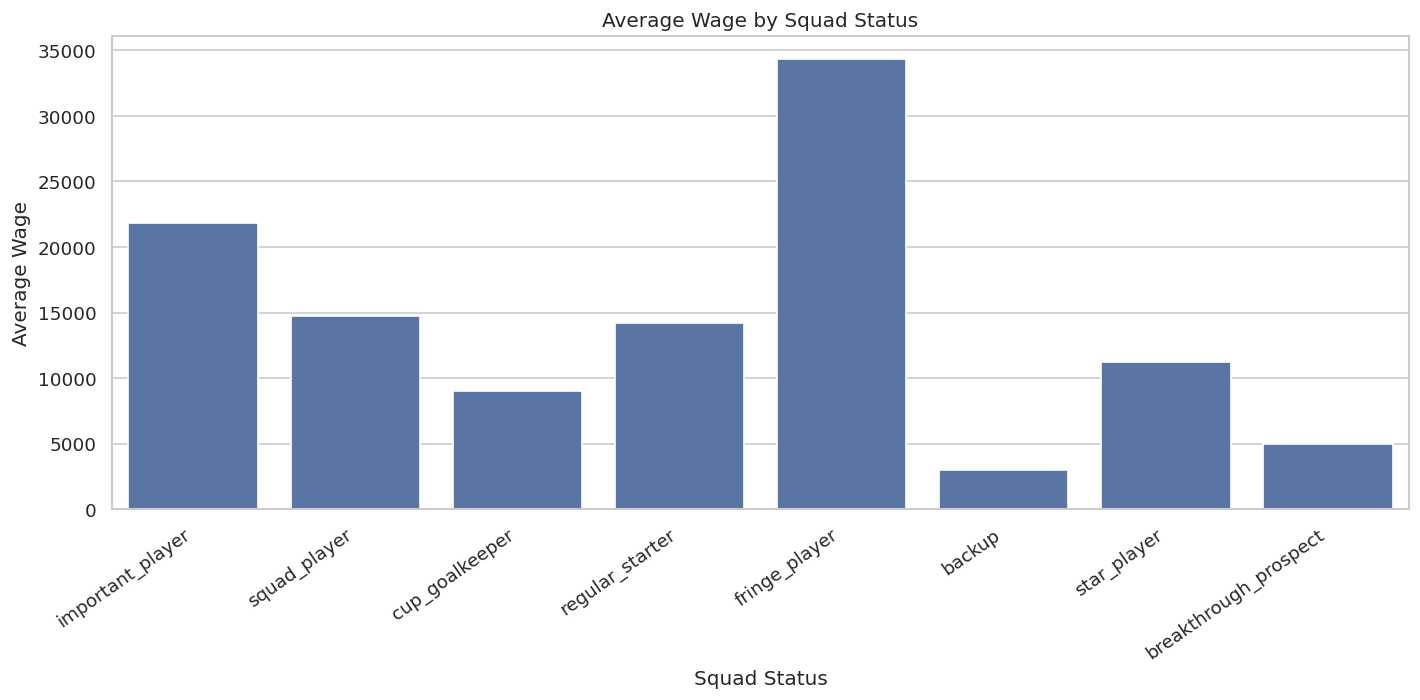

In [40]:

# 04.11 — Contract Expiry and Wage Analysis

# Convert contract end dates to datetime
df["contract_end"] = pd.to_datetime(
    df["contract_end"],
    errors="coerce"
)

# Extract contract expiry year
df["contract_expiry_year"] = df["contract_end"].dt.year

# Contract expiry distribution
expiry_summary = (
    df["contract_expiry_year"]
    .value_counts()
    .sort_index()
    .reset_index()
)

expiry_summary.columns = ["Contract Expiry Year", "Player Count"]

print("Contract Expiry Distribution:")
display(expiry_summary)

# Prepare wage analysis
df["contract_wage"] = pd.to_numeric(
    df["contract_wage"],
    errors="coerce"
)

wage_analysis = df[
    [
        "player_name",
        "age",
        "contract_squad_status",
        "contract_wage"
    ]
].sort_values(
    by="contract_wage",
    ascending=False
)

print("\nTop 10 Highest-Paid Players:")
display(wage_analysis.head(10))

# Visualize wage distribution by squad status
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="contract_squad_status",
    y="contract_wage",
    estimator="mean",
    errorbar=None
)

plt.title("Average Wage by Squad Status")
plt.xlabel("Squad Status")
plt.ylabel("Average Wage")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



## 04.12 — Squad Analysis Summary

### Key Findings

**1. Squad Age Profile**

- The analyzed dataset contains 26 players.
- Average player age is approximately 24.73 years.
- The largest age group is 21–24, with 11 players.
- 20 out of 26 players are below 29 years old.

**2. Current Ability and Potential Ability**

- Pelle Mattsson has the highest Current Ability (132) among the analyzed players.
- Kellen Fisher and Mathias Kvistgaarden have the largest development gaps among the top 15 players by Current Ability, at 23 points.
- Vicente Reyes and Lucien Mahovo have the largest overall development gaps, at 28 points.

**3. Positional Distribution**

- Midfield has the highest number of natural position records, with 14.
- Defence and Attack each have 10 records.
- Goalkeeper has 3 records.
- The distribution suggests that midfield is the most represented area in the analyzed dataset.

**4. Contract and Squad Status**

- Most analyzed players are classified as squad players, important players, or regular starters.
- Only one player is currently listed as being on loan.
- Two players have contracts expiring in 2027.
- Seven players each have contracts expiring in 2028, 2029, and 2030.

**5. Wage Structure**

- Anthony Musaba has the highest recorded wage at 34,361.
- His current squad status is fringe player.
- This may warrant further evaluation of wage allocation and squad contribution.

### Overall Conclusion

The analysis indicates that Norwich City's analyzed player group has a relatively young age profile and a strong concentration of natural position records in midfield.

Several young players show considerable potential development gaps, while contract expiry dates are distributed across multiple seasons.

Further evaluation should focus on squad depth, player development, contract planning, and wage efficiency.

*Note: All findings are based on 26 players with available performance records from a Football Manager 2027 save. They do not represent the complete 82-player squad database.*


In [41]:

# 05.02 — Recruitment Data Preparation

# Select relevant recruitment and performance metrics
recruitment_columns = [
    "player_name",
    "age",
    "natural_positions",
    "minutes",
    "goals",
    "assists",
    "expected_goals",
    "expected_assists",
    "average_rating",
    "ability_current",
    "ability_potential",
    "transfer_value",
    "contract_wage",
    "contract_squad_status"
]

# Create recruitment dataset
recruitment_df = df[recruitment_columns].copy()

# Convert numerical columns
numeric_columns = [
    "age",
    "minutes",
    "goals",
    "assists",
    "expected_goals",
    "expected_assists",
    "average_rating",
    "ability_current",
    "ability_potential",
    "transfer_value",
    "contract_wage"
]

for column in numeric_columns:
    recruitment_df[column] = pd.to_numeric(
        recruitment_df[column],
        errors="coerce"
    )

# Calculate attacking contributions
recruitment_df["goal_contributions"] = (
    recruitment_df["goals"] +
    recruitment_df["assists"]
)

# Calculate goal contributions per 90 minutes
recruitment_df["goal_contributions_per90"] = (
    recruitment_df["goal_contributions"] /
    recruitment_df["minutes"].replace(0, np.nan)
) * 90

# Display dataset overview
print("Recruitment Dataset Shape:", recruitment_df.shape)

print("\nRecruitment Dataset Preview:")
display(recruitment_df.head(10))

print("\nMissing Values:")
display(
    recruitment_df.isnull().sum().to_frame(
        name="Missing Values"
    )
)


Recruitment Dataset Shape: (26, 16)

Recruitment Dataset Preview:


,player_name,age,natural_positions,minutes,goals,assists,expected_goals,expected_assists,average_rating,ability_current,ability_potential,transfer_value,contract_wage,contract_squad_status,goal_contributions,goal_contributions_per90
0,Vladan Kovačević,29,GK,3956,0,0,0.00,0.00,6.920455,121,130,5238860,31500,important_player,0,0.000000
1,Ante Crnac,23,AMR;STC,951,3,3,2.34,3.41,7.064706,120,145,9930201,12000,squad_player,6,0.567823
2,Pelle Mattsson,25,DM;MC,3186,4,2,2.99,2.93,7.230556,132,148,17918683,22173,important_player,6,0.169492
3,Mathias Kvistgaarden,25,STC,238,1,2,0.84,0.52,6.822222,119,142,10522564,17000,squad_player,3,1.134454
4,Jack Stacey,31,DR,1212,0,1,0.28,1.39,6.737500,114,138,484254,25000,squad_player,1,0.074257
5,Daniel Grimshaw,29,GK,454,0,0,0.00,0.00,6.983333,108,130,610795,9000,cup_goalkeeper,0,0.000000
6,Sam Field,28,DM;MC,1236,3,0,1.74,1.58,7.041176,116,140,6299640,13000,squad_player,3,0.218447
7,Paris Maghoma,25,AMC,160,0,0,0.54,0.18,6.700000,122,140,5886000,10000,regular_starter,0,0.000000
8,Andre Brooks,23,MC;AMR,2727,4,14,3.19,10.83,7.127778,128,135,12533730,27000,important_player,18,0.594059
9,Harry Darling,27,DC,3870,0,0,0.73,0.79,7.016279,116,135,6014257,16000,squad_player,0,0.000000



Missing Values:


,Missing Values
player_name,0
age,0
natural_positions,0
minutes,0
goals,0
assists,0
expected_goals,0
expected_assists,0
average_rating,0
ability_current,0


In [42]:

# 05.03 — Attacking Player Value Analysis

# Define attacking positions
attacking_positions = ["STC", "AML", "AMR", "AMC"]

# Filter attacking players with at least 900 minutes
attacking_players = recruitment_df[
    recruitment_df["natural_positions"].apply(
        lambda positions: any(
            position in positions.split(";")
            for position in attacking_positions
        )
    ) &
    (recruitment_df["minutes"] >= 900)
].copy()

# Calculate attacking contribution relative to transfer value
attacking_players["contributions_per_million"] = (
    attacking_players["goal_contributions"] /
    (attacking_players["transfer_value"] / 1_000_000)
)

# Sort players by goal contributions per 90
attacking_ranking = attacking_players.sort_values(
    by="goal_contributions_per90",
    ascending=False
)

# Display attacking player value analysis
value_columns = [
    "player_name",
    "age",
    "minutes",
    "goal_contributions",
    "goal_contributions_per90",
    "ability_current",
    "transfer_value",
    "contributions_per_million"
]

print("Attacking Player Value Ranking:")
display(attacking_ranking[value_columns])

print("\nNumber of eligible attacking players:",
      len(attacking_players))


Attacking Player Value Ranking:


,player_name,age,minutes,goal_contributions,goal_contributions_per90,ability_current,transfer_value,contributions_per_million
16,Mohamed Touré,23,2856,43,1.355042,131,21493100,2.000642
17,Jovon Makama,23,1550,19,1.103226,124,14659040,1.296129
22,Oscar Schwartau,20,3089,22,0.640984,129,19409334,1.133475
8,Andre Brooks,23,2727,18,0.594059,128,12533730,1.436125
1,Ante Crnac,23,951,6,0.567823,120,9930201,0.604217
10,Anthony Musaba,26,1818,11,0.544554,120,2063737,5.330137



Number of eligible attacking players: 6


Performance vs Transfer Value:


,player_name,age,minutes,average_rating,ability_current,transfer_value_millions,contract_wage
16,Mohamed Touré,23,2856,7.371053,131,21.493100,10000
22,Oscar Schwartau,20,3089,7.245946,129,19.409334,11250
18,Ben Chrisene,23,2996,7.244444,121,6.951688,18000
2,Pelle Mattsson,25,3186,7.230556,132,17.918683,22173
21,Kellen Fisher,22,3288,7.223684,127,15.716895,10000
19,José Córdoba,25,2790,7.129032,123,11.802780,22167
8,Andre Brooks,23,2727,7.127778,128,12.533730,27000
12,Kenny McLean,35,3475,7.125000,116,1.329853,25000
15,Ruairi McConville,22,3961,7.093182,129,11.860100,18750
1,Ante Crnac,23,951,7.064706,120,9.930201,12000


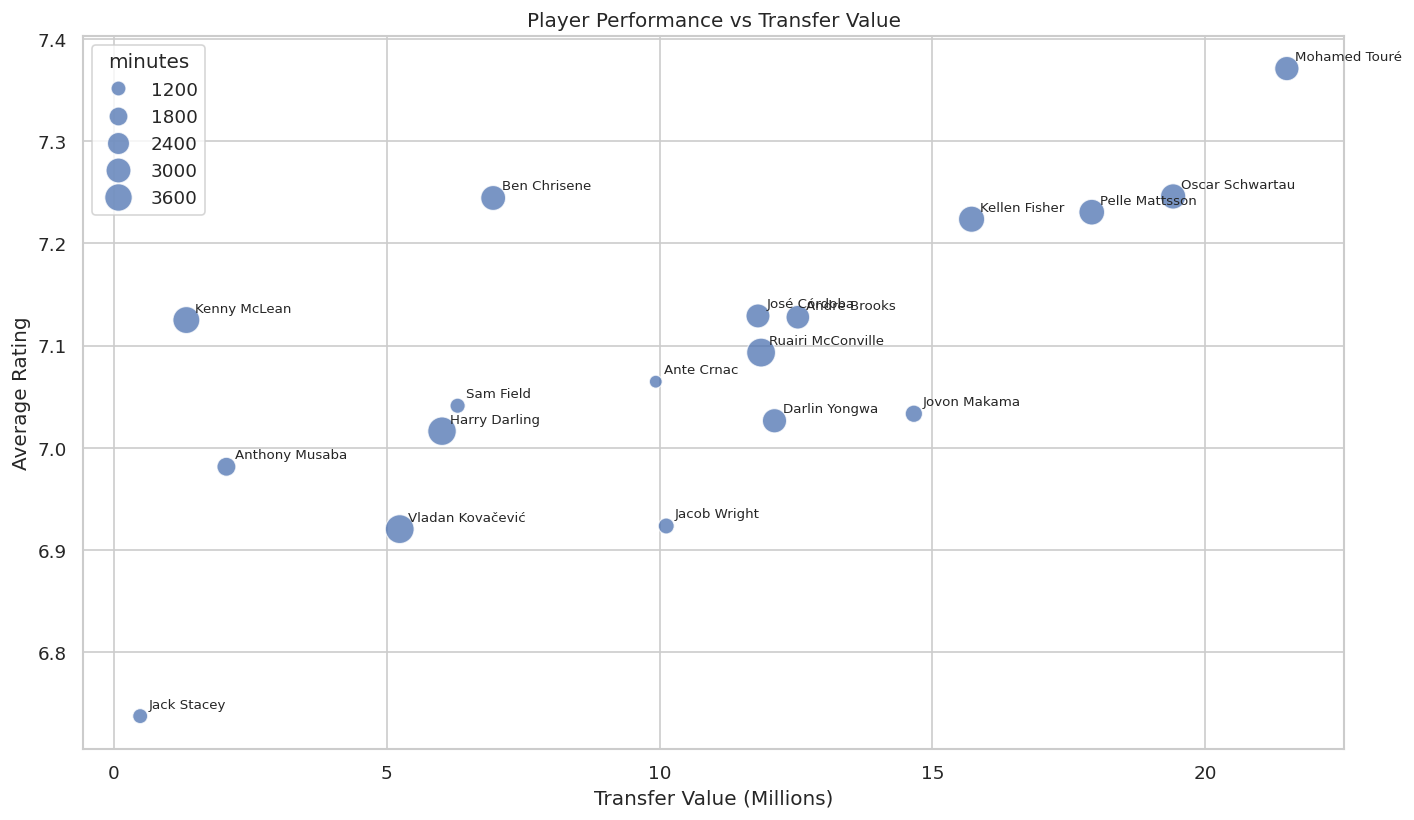

In [43]:

# 05.04 — Performance vs Transfer Value

# Filter players with sufficient playing time
value_comparison = recruitment_df[
    recruitment_df["minutes"] >= 900
].copy()

# Convert transfer value into millions
value_comparison["transfer_value_millions"] = (
    value_comparison["transfer_value"] / 1_000_000
)

# Sort players by average rating
performance_ranking = value_comparison.sort_values(
    by="average_rating",
    ascending=False
)

# Display performance and transfer value comparison
comparison_columns = [
    "player_name",
    "age",
    "minutes",
    "average_rating",
    "ability_current",
    "transfer_value_millions",
    "contract_wage"
]

print("Performance vs Transfer Value:")
display(performance_ranking[comparison_columns])

# Create scatter plot
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=value_comparison,
    x="transfer_value_millions",
    y="average_rating",
    size="minutes",
    sizes=(60, 300),
    alpha=0.75
)

# Label the players
for _, player in value_comparison.iterrows():
    plt.annotate(
        player["player_name"],
        (
            player["transfer_value_millions"],
            player["average_rating"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title("Player Performance vs Transfer Value")
plt.xlabel("Transfer Value (Millions)")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()


In [44]:

# 05.05 — Midfield Performance Analysis

# Define midfield positions
midfield_positions = ["DM", "MC", "AMC"]

# Filter midfield players with at least 900 minutes
midfield_players = recruitment_df[
    recruitment_df["natural_positions"].apply(
        lambda positions: any(
            position in positions.split(";")
            for position in midfield_positions
        )
    ) &
    (recruitment_df["minutes"] >= 900)
].copy()

# Calculate attacking contributions
midfield_players["goal_contributions"] = (
    midfield_players["goals"] +
    midfield_players["assists"]
)

# Sort by average rating
midfield_ranking = midfield_players.sort_values(
    by="average_rating",
    ascending=False
)

# Display midfield performance ranking
midfield_columns = [
    "player_name",
    "age",
    "natural_positions",
    "minutes",
    "goals",
    "assists",
    "expected_assists",
    "average_rating",
    "ability_current",
    "transfer_value"
]

print("Midfield Performance Ranking:")
display(midfield_ranking[midfield_columns])

print("\nNumber of eligible midfield players:",
      len(midfield_players))


Midfield Performance Ranking:


,player_name,age,natural_positions,minutes,goals,assists,expected_assists,average_rating,ability_current,transfer_value
22,Oscar Schwartau,20,AML;AMC,3089,10,12,9.57,7.245946,129,19409334
2,Pelle Mattsson,25,DM;MC,3186,4,2,2.93,7.230556,132,17918683
8,Andre Brooks,23,MC;AMR,2727,4,14,10.83,7.127778,128,12533730
12,Kenny McLean,35,DM;MC,3475,6,7,5.21,7.125000,116,1329853
6,Sam Field,28,DM;MC,1236,3,0,1.58,7.041176,116,6299640
24,Jacob Wright,21,DM;MC,1350,2,2,2.05,6.923529,118,10121880



Number of eligible midfield players: 6


In [45]:

# 05.06 — Defensive Performance Analysis

# Define defensive positions
defensive_positions = ["DC", "DL", "DR", "WBL", "WBR"]

# Filter defensive players with at least 900 minutes
defensive_players = recruitment_df[
    recruitment_df["natural_positions"].apply(
        lambda positions: any(
            position in positions.split(";")
            for position in defensive_positions
        )
    ) &
    (recruitment_df["minutes"] >= 900)
].copy()

# Sort by average rating
defensive_ranking = defensive_players.sort_values(
    by="average_rating",
    ascending=False
)

# Select relevant defensive metrics
defensive_columns = [
    "player_name",
    "age",
    "natural_positions",
    "minutes",
    "average_rating",
    "ability_current",
    "ability_potential",
    "transfer_value",
    "contract_wage"
]

# Display defensive performance ranking
print("Defensive Performance Ranking:")
display(defensive_ranking[defensive_columns])

print("\nNumber of eligible defensive players:",
      len(defensive_players))


Defensive Performance Ranking:


,player_name,age,natural_positions,minutes,average_rating,ability_current,ability_potential,transfer_value,contract_wage
18,Ben Chrisene,23,DL;WBL,2996,7.244444,121,135,6951688,18000
21,Kellen Fisher,22,DR;WBR,3288,7.223684,127,150,15716895,10000
19,José Córdoba,25,DC,2790,7.129032,123,145,11802780,22167
15,Ruairi McConville,22,DC,3961,7.093182,129,150,11860100,18750
11,Darlin Yongwa,26,DL,2854,7.026471,122,134,12105720,15000
9,Harry Darling,27,DC,3870,7.016279,116,135,6014257,16000
4,Jack Stacey,31,DR,1212,6.737500,114,138,484254,25000



Number of eligible defensive players: 7


In [46]:

# 05.07 — Goalkeeper Performance Analysis

# Filter goalkeepers with at least 900 minutes
goalkeepers = recruitment_df[
    recruitment_df["natural_positions"].apply(
        lambda positions: "GK" in positions.split(";")
    ) &
    (recruitment_df["minutes"] >= 900)
].copy()

# Sort by average rating
goalkeeper_ranking = goalkeepers.sort_values(
    by="average_rating",
    ascending=False
)

# Select relevant goalkeeper metrics
goalkeeper_columns = [
    "player_name",
    "age",
    "minutes",
    "average_rating",
    "ability_current",
    "ability_potential",
    "transfer_value",
    "contract_wage",
    "contract_squad_status"
]

# Display goalkeeper analysis
print("Goalkeeper Performance Ranking:")
display(goalkeeper_ranking[goalkeeper_columns])

print("\nNumber of eligible goalkeepers:", len(goalkeepers))


Goalkeeper Performance Ranking:


,player_name,age,minutes,average_rating,ability_current,ability_potential,transfer_value,contract_wage,contract_squad_status
0,Vladan Kovačević,29,3956,6.920455,121,130,5238860,31500,important_player



Number of eligible goalkeepers: 1


In [47]:

# 05.08 — Recruitment & Squad Planning Shortlist

# Calculate potential development gap
recruitment_df["development_gap"] = (
    recruitment_df["ability_potential"] -
    recruitment_df["ability_current"]
)

# Category 1: High-performing young assets
high_performing_assets = recruitment_df[
    (recruitment_df["age"] <= 25) &
    (recruitment_df["average_rating"] >= 7.20) &
    (recruitment_df["minutes"] >= 900)
].sort_values(
    by="average_rating",
    ascending=False
)

# Category 2: Young players with significant development potential
development_candidates = recruitment_df[
    (recruitment_df["age"] <= 23) &
    (recruitment_df["development_gap"] >= 20)
].sort_values(
    by="development_gap",
    ascending=False
)

# Category 3: Players who may require further evaluation
review_candidates = recruitment_df[
    (recruitment_df["age"] >= 29) |
    (recruitment_df["average_rating"] < 6.90)
].sort_values(
    by="average_rating",
    ascending=True
)

# Select columns for reporting
shortlist_columns = [
    "player_name",
    "age",
    "minutes",
    "average_rating",
    "ability_current",
    "ability_potential",
    "development_gap",
    "transfer_value",
    "contract_wage"
]

print("HIGH-PERFORMING ASSETS:")
display(high_performing_assets[shortlist_columns])

print("\nDEVELOPMENT CANDIDATES:")
display(development_candidates[shortlist_columns])

print("\nREVIEW CANDIDATES:")
display(review_candidates[shortlist_columns])


HIGH-PERFORMING ASSETS:


,player_name,age,minutes,average_rating,ability_current,ability_potential,development_gap,transfer_value,contract_wage
16,Mohamed Touré,23,2856,7.371053,131,145,14,21493100,10000
22,Oscar Schwartau,20,3089,7.245946,129,150,21,19409334,11250
18,Ben Chrisene,23,2996,7.244444,121,135,14,6951688,18000
2,Pelle Mattsson,25,3186,7.230556,132,148,16,17918683,22173
21,Kellen Fisher,22,3288,7.223684,127,150,23,15716895,10000



DEVELOPMENT CANDIDATES:


,player_name,age,minutes,average_rating,ability_current,ability_potential,development_gap,transfer_value,contract_wage
14,Vicente Reyes,23,90,6.400000,87,115,28,13618,3000
25,Lucien Mahovo,21,720,7.187500,112,140,28,4865634,5000
24,Jacob Wright,21,1350,6.923529,118,145,27,10121880,12000
23,Gabe Forsyth,20,90,7.600000,110,137,27,2674329,5000
1,Ante Crnac,23,951,7.064706,120,145,25,9930201,12000
20,Papa Amadou Diallo,22,111,7.200000,116,141,25,4956160,15000
21,Kellen Fisher,22,3288,7.223684,127,150,23,15716895,10000
17,Jovon Makama,23,1550,7.033333,124,145,21,14659040,16327
15,Ruairi McConville,22,3961,7.093182,129,150,21,11860100,18750
22,Oscar Schwartau,20,3089,7.245946,129,150,21,19409334,11250



REVIEW CANDIDATES:


,player_name,age,minutes,average_rating,ability_current,ability_potential,development_gap,transfer_value,contract_wage
14,Vicente Reyes,23,90,6.400000,87,115,28,13618,3000
7,Paris Maghoma,25,160,6.700000,122,140,18,5886000,10000
4,Jack Stacey,31,1212,6.737500,114,138,24,484254,25000
3,Mathias Kvistgaarden,25,238,6.822222,119,142,23,10522564,17000
0,Vladan Kovačević,29,3956,6.920455,121,130,9,5238860,31500
5,Daniel Grimshaw,29,454,6.983333,108,130,22,610795,9000
12,Kenny McLean,35,3475,7.125000,116,130,14,1329853,25000


In [48]:

# 05.08 — Recruitment Priority Summary

# Define positional groups
position_groups = {
    "Goalkeeper": ["GK"],
    "Defence": ["DC", "DL", "DR", "WBL", "WBR"],
    "Midfield": ["DM", "MC", "AMC"],
    "Attack": ["STC", "AML", "AMR", "AMC"]
}

# Build positional summary
priority_summary = []

for group, positions in position_groups.items():
    group_players = recruitment_df[
        recruitment_df["natural_positions"].apply(
            lambda player_positions: any(
                position in player_positions.split(";")
                for position in positions
            )
        )
    ].copy()

    eligible_players = group_players[
        group_players["minutes"] >= 900
    ]

    priority_summary.append({
        "position_group": group,
        "players_in_dataset": len(group_players),
        "players_900_plus_minutes": len(eligible_players),
        "average_rating": round(
            eligible_players["average_rating"].mean(), 2
        ),
        "average_age": round(
            eligible_players["age"].mean(), 1
        )
    })

priority_df = pd.DataFrame(priority_summary)

print("Recruitment Priority Summary:")
display(priority_df)


Recruitment Priority Summary:


,position_group,players_in_dataset,players_900_plus_minutes,average_rating,average_age
0,Goalkeeper,3,1,6.92,29.0
1,Defence,8,7,7.07,25.1
2,Midfield,9,6,7.12,25.3
3,Attack,9,6,7.14,23.0



## 05.9 Recruitment & Scouting Analysis — Key Findings

### 1. High-Performing Assets

Several players demonstrated strong performance and long-term value:

- Mohamed Touré was the highest-performing attacking asset, recording 43 goal contributions and a 7.37 average rating.
- Oscar Schwartau showed an excellent combination of age, performance, and potential ability.
- Ben Chrisene delivered a 7.24 average rating with a relatively moderate estimated transfer value.
- Pelle Mattsson provided strong midfield performance with a Current Ability of 132.
- Kellen Fisher combined consistent playing time with a Potential Ability of 150.

### 2. Development Candidates

Players such as Lucien Mahovo, Jacob Wright, Gabe Forsyth, and Ante Crnac showed significant development gaps between Current Ability and Potential Ability.

These players represent possible long-term development assets, although playing time and actual development progress should continue to be monitored.

### 3. Squad Review Candidates

Several players require further evaluation based on age, playing time, performance, wages, and squad status.

Jack Stacey and Kenny McLean are notable examples for different reasons: Stacey recorded a relatively low average rating, while McLean's age suggests a need for succession planning.

Players with limited minutes should not be considered underperformers based on rating alone.

### 4. Recruitment Priorities

The positional analysis identified the following areas for further investigation:

- Goalkeeper: Evaluate long-term succession and competition for the starting position.
- Midfield: Prepare for the eventual replacement of experienced players.
- Defence: Maintain squad depth and monitor player development.
- Attack: Retain productive attacking assets and prioritize internal development.

### 5. Overall Conclusion

Norwich City has a relatively young group of high-performing players, particularly in attacking and defensive areas.

The recruitment analysis suggests that the club should prioritize long-term squad planning, goalkeeper succession, and midfield regeneration rather than making unnecessary changes to every position.

The findings are based on Football Manager 2027 save data and should be interpreted as an in-game recruitment analysis rather than real-world player evaluations.

**Data limitation:** This analysis covers 26 players with available performance records, not the entire 82-player squad database. A minimum playing-time threshold of 900 minutes was applied to most performance comparisons.



# 06. Conclusion & Recommendations

This section summarizes the key findings from the Norwich City Football Analytics project.

The objective is to combine player performance analysis, squad evaluation, and recruitment insights into practical recommendations for squad planning.

The analysis covers:

- Overall team and player performance.
- Individual player contributions and efficiency.
- Squad age distribution and ability profiles.
- Positional depth and squad structure.
- Recruitment priorities and player development opportunities.


In [49]:

# 06.02 — Key Performance Findings

# Identify the highest-performing players
top_performers = eligible_players.sort_values(
    by="average_rating",
    ascending=False
).head(5)

# Display key performance metrics
performance_summary = top_performers[
    [
        "player_name",
        "age",
        "minutes",
        "goals",
        "assists",
        "goal_contributions",
        "average_rating"
    ]
].copy()

print("Top 5 Players by Average Rating:")
display(performance_summary)

# Identify the player with the highest goal contributions
top_contributor = df.loc[
    df["goal_contributions"].idxmax()
]

print("\nHighest Goal Contributor:")
print(top_contributor["player_name"])
print("Goal Contributions:", top_contributor["goal_contributions"])

# Identify the most utilized player
most_utilized = df.loc[df["minutes"].idxmax()]

print("\nMost Utilized Player:")
print(most_utilized["player_name"])
print("Minutes Played:", most_utilized["minutes"])


Top 5 Players by Average Rating:


,player_name,age,minutes,goals,assists,goal_contributions,average_rating
16,Mohamed Touré,23,2856,40,3,43,7.371053
22,Oscar Schwartau,20,3089,10,12,22,7.245946
8,Andre Brooks,23,2727,4,14,18,7.127778
1,Ante Crnac,23,951,3,3,6,7.064706
17,Jovon Makama,23,1550,17,2,19,7.033333



Highest Goal Contributor:
Mohamed Touré
Goal Contributions: 43

Most Utilized Player:
Ruairi McConville
Minutes Played: 3961


In [50]:

# 06.03 — Squad Structure Summary

# Calculate squad profile metrics
squad_summary = {
    "total_players_analyzed": len(df),
    "average_age": round(df["age"].mean(), 2),
    "average_current_ability": round(
        df["ability_current"].mean(), 2
    ),
    "average_potential_ability": round(
        df["ability_potential"].mean(), 2
    ),
    "players_under_25": int((df["age"] < 25).sum()),
    "players_under_29": int((df["age"] < 29).sum()),
    "players_with_ability_gap_20_plus": int(
        ((df["ability_potential"] - df["ability_current"]) >= 20).sum()
    )
}

print("Squad Structure Summary:")

for metric, value in squad_summary.items():
    print(f"{metric}: {value}")


Squad Structure Summary:
total_players_analyzed: 26
average_age: 24.73
average_current_ability: 119.12
average_potential_ability: 138.88
players_under_25: 13
players_under_29: 22
players_with_ability_gap_20_plus: 16


In [51]:

# 06.04 — Recruitment & Squad Planning Summary

# Filter players with sufficient playing time
eligible_summary = df[df["minutes"] >= 900].copy()

# Calculate development gap
df["development_gap"] = (
    df["ability_potential"] - df["ability_current"]
)

eligible_summary["development_gap"] = (
    eligible_summary["ability_potential"] -
    eligible_summary["ability_current"]
)

# Best performer with minimum playing time
best_performer = eligible_summary.loc[
    eligible_summary["average_rating"].idxmax()
]

# All players with the largest development gap
max_gap = df["development_gap"].max()

biggest_development_gap = df[
    df["development_gap"] == max_gap
][[
    "player_name",
    "age",
    "ability_current",
    "ability_potential",
    "development_gap"
]]

# Highest recorded wage
highest_wage_player = df.loc[
    df["contract_wage"].idxmax()
]

# Position with the fewest eligible players
priority_position = priority_df.loc[
    priority_df["players_900_plus_minutes"].idxmin()
]

print("RECRUITMENT & SQUAD PLANNING SUMMARY")

print("\nBest Performer (900+ minutes):")
print(best_performer["player_name"])
print("Average Rating:", round(best_performer["average_rating"], 2))

print("\nHighest Single Average Rating:")
raw_best = df.loc[df["average_rating"].idxmax()]
print(raw_best["player_name"])
print("Average Rating:", round(raw_best["average_rating"], 2))
print("Minutes:", raw_best["minutes"])

print("\nLargest Development Gap:")
display(biggest_development_gap)

print("\nHighest Recorded Wage:")
print(highest_wage_player["player_name"])
print("Recorded Wage:", highest_wage_player["contract_wage"])

print("\nPosition with Fewest Eligible Players:")
print(priority_position["position_group"])
print("Eligible Players:", priority_position["players_900_plus_minutes"])


RECRUITMENT & SQUAD PLANNING SUMMARY

Best Performer (900+ minutes):
Mohamed Touré
Average Rating: 7.37

Highest Single Average Rating:
Gabe Forsyth
Average Rating: 7.6
Minutes: 90

Largest Development Gap:


,player_name,age,ability_current,ability_potential,development_gap
14,Vicente Reyes,23,87,115,28
25,Lucien Mahovo,21,112,140,28



Highest Recorded Wage:
Anthony Musaba
Recorded Wage: 34361

Position with Fewest Eligible Players:
Goalkeeper
Eligible Players: 1



## 06.05 — Final Conclusion & Recommendations

### 1. Overall Performance

Mohamed Touré emerged as Norwich City's most outstanding player during the analyzed season.

He recorded 40 goals, 3 assists, and 43 total goal contributions across 2,856 minutes, with an average rating of 7.37.

Oscar Schwartau and Andre Brooks also demonstrated strong attacking contributions, highlighting the team's offensive strengths.

Ruairi McConville was the most utilized player, recording 3,961 minutes throughout the season.

### 2. Squad Structure and Development

The analyzed squad consisted of 26 players with an average age of 24.73 years.

The squad demonstrated considerable development potential:

- 22 players were under 29 years old.
- 16 players had a development gap of at least 20 points.
- Average Current Ability was 119.12.
- Average Potential Ability was 138.88.

These findings suggest that Norwich has a relatively young player group with opportunities for long-term development.

### 3. Recruitment and Squad Planning

The recruitment analysis identified several important considerations:

- Goalkeeper succession should be investigated, as only one goalkeeper met the 900-minute threshold.
- Midfield succession planning is important due to Kenny McLean's age.
- Young players such as Lucien Mahovo, Jacob Wright, and Gabe Forsyth represent potential development opportunities.
- High-performing players such as Mohamed Touré, Oscar Schwartau, and Kellen Fisher should be considered important long-term assets.
- Wage allocation should be reviewed alongside player performance, squad status, and contract conditions.

### 4. Strategic Recommendations

Based on the findings, the following actions are recommended:

1. Maintain the core group of high-performing players.
2. Prioritize goalkeeper succession planning.
3. Develop younger players through appropriate playing opportunities.
4. Prepare long-term replacements for aging squad members.
5. Evaluate recruitment decisions using performance, ability, age, estimated transfer value, and wage data.

### 5. Final Conclusion

This project demonstrates how Football Manager 2027 save data can be transformed into a structured football analytics workflow.

By combining exploratory data analysis, player performance evaluation, squad profiling, and recruitment analysis, the project provides a data-driven overview of Norwich City's squad strengths, development opportunities, and potential recruitment priorities.

The findings indicate that Norwich possesses a relatively young and promising squad, with strong attacking assets and several players offering significant development potential.

However, goalkeeper succession and long-term midfield planning remain important areas for further investigation.

**Data Disclaimer:** All findings are based on Football Manager 2027 save data and represent an in-game analytical case study. They should not be interpreted as official real-world player performance or market valuations.

**Data Scope:** The analysis focuses on 26 players with available performance records, matched against a larger squad profile dataset. Performance comparisons generally use a minimum threshold of 900 playing minutes.
